# Granular Exploratory Data Analysis & Feature Engineering Pipeline
## Real-Time Fake PTP Detection — CreditNirvana

### Executive Summary
This notebook documents a comprehensive, end-to-end analytical pipeline designed to identify "Fake" Promises to Pay (PTPs) in real-time. By systematically merging call metadata, agent behaviors, conversational linguistics (NLP), financial history, and post-call digital engagement, we construct a robust feature space. We employ rigorous statistical testing (e.g., Kruskal-Wallis, Chi-Square, Information Theory metrics) to validate feature predictive power before modeling.

> **Methodological Note on Data Leakage:** All distributional analysis, hypothesis testing, and threshold discovery are strictly confined to the **training split**. Engineered features are applied uniformly across validation and test sets in the ML pipeline.

## 0. Environment Setup & Mathematical Utilities
We begin by establishing our computational environment. This includes importing necessary libraries for data manipulation, statistical analysis, natural language processing, and machine learning. We also define custom mathematical functions (like Shannon entropy) that will be used to quantify dataset imbalances later in our exploratory analysis.

In [274]:
import math
import os
import re
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, entropy, kruskal, mannwhitneyu

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.0)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 5)

PRIMARY_NAVY = "#1B2A4A"
ACCENT_CORAL = "#E05638"
ACCENT_GREEN = "#2A9D8F"


### Mathematical Helper Functions
We define robust statistical utilities such as Wilson score intervals for proportion confidence, and date parsers for handling non-standard timestamps.

In [275]:
def wilson_ci(k: int, n: int, confidence: float = 0.95) -> tuple:
    """Wilson score interval for a binomial proportion."""
    if n == 0:
        return (0.0, 0.0)
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = (z * math.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)) / denom
    return (max(0.0, centre - margin), min(1.0, centre + margin))


def format_ci(ci):
    return f"[{ci[0]*100:.1f}%, {ci[1]*100:.1f}%]"


### Timestamp Parsing Utility
We define a utility to safely parse and standardize mixed date formats into Pandas datetime objects.

In [276]:
def parse_ts(s: pd.Series) -> pd.Series:
    """Parse mixed timestamp formats safely."""
    s = s.astype("string")
    iso = s.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    if iso.any():
        out[iso] = pd.to_datetime(s[iso], format="mixed", errors="coerce")
    if (~iso).any():
        out[~iso] = pd.to_datetime(s[~iso], dayfirst=True, format="mixed", errors="coerce")
    return out


print("Environment and helper functions initialized successfully.")


Environment and helper functions initialized successfully.


## 1. Data Ingestion & Unification
### 1.1 Load and Validate Raw Data
The raw data exists in a normalized, star-schema-like structure across multiple CSV files (PTP records, dial attempts, demographics, etc.). Our first step is to ingest these disparate sources into memory and validate their integrity.

In [277]:
# Load all datasets from known paths
ptps_raw = pd.read_csv("data/ps1_fake_ptp/ptps.csv")
dial_raw = pd.read_csv("data/shared/dial_attempts.csv")
transcripts_raw = pd.read_csv("data/ps1_fake_ptp/call_transcripts.csv")
accounts_raw = pd.read_csv("data/shared/accounts.csv")
agents_raw = pd.read_csv("data/shared/agents.csv")
lenders_raw = pd.read_csv("data/shared/lenders.csv")
splits_raw = pd.read_csv("data/shared/splits.csv")
payments_raw = pd.read_csv("data/shared/payments.csv")
post_call_raw = pd.read_csv("data/ps1_fake_ptp/post_call_events.csv")
annotated_raw = pd.read_csv("data/ps1_fake_ptp/annotated_ptp_sample.csv")

print("All datasets loaded:")
for name, df in [("PTPs", ptps_raw), ("Dial Attempts", dial_raw),
                  ("Transcripts", transcripts_raw), ("Accounts", accounts_raw),
                  ("Agents", agents_raw), ("Lenders", lenders_raw),
                  ("Splits", splits_raw), ("Payments", payments_raw),
                  ("Post-Call Events", post_call_raw), ("Annotated", annotated_raw)]:
    print(f"  {name:<18} | Rows: {df.shape[0]:<6} | Cols: {df.shape[1]}")

All datasets loaded:
  PTPs               | Rows: 3696   | Cols: 13
  Dial Attempts      | Rows: 51105  | Cols: 16
  Transcripts        | Rows: 39194  | Cols: 8
  Accounts           | Rows: 2400   | Cols: 20
  Agents             | Rows: 30     | Cols: 6
  Lenders            | Rows: 6      | Cols: 4
  Splits             | Rows: 2400   | Cols: 2
  Payments           | Rows: 2162   | Cols: 5
  Post-Call Events   | Rows: 8466   | Cols: 3
  Annotated          | Rows: 200    | Cols: 3


### 1.2 Standardize Timestamps
Temporal features are critical in behavioral modeling. We parse and standardize all timestamps to datetime objects. This alignment is necessary to engineer time-based features such as "time to hangup", shift-bunching indicators, and post-call grace periods.

In [278]:
ptps_raw["captured_ts"] = parse_ts(ptps_raw["captured_ts"])
ptps_raw["promised_date"] = parse_ts(ptps_raw["promised_date"])
dial_raw["attempt_ts"] = parse_ts(dial_raw["attempt_ts"])
payments_raw["payment_ts"] = parse_ts(payments_raw["payment_ts"])
post_call_raw["event_ts"] = parse_ts(post_call_raw["event_ts"])

print("Timestamps standardized.")
ptps_raw[["captured_ts", "promised_date"]].head(3)

Timestamps standardized.


,captured_ts,promised_date
0,2026-04-01 10:54:30,2026-04-03
1,2026-04-01 09:11:48,2026-04-08
2,2026-04-01 12:29:36,2026-04-03


### 1.3 Construct Master PTP DataFrame
To perform a cohesive analysis, we denormalize the data. Anchoring on `ptp_id` as our primary key (the granular level of analysis), we sequentially merge dial-attempt metadata, account information, and human annotation labels into a unified master analytical view.

In [279]:
# Start with PTPs as the grain
master_df = ptps_raw.copy()

# Merge dial attempts (drop columns that overlap to avoid _x/_y suffixes)
dial_merge_cols = [c for c in dial_raw.columns
                   if c not in master_df.columns or c == "attempt_id"]
master_df = master_df.merge(dial_raw[dial_merge_cols], on="attempt_id", how="left")

# Merge accounts (drop dialling_arm if it already exists from dial)
acc_merge_cols = [c for c in accounts_raw.columns if c not in master_df.columns or c == "account_id"]
master_df = master_df.merge(accounts_raw[acc_merge_cols], on="account_id", how="left")


### Merge Entity Demographics
Next, we merge lender-specific risk profiles and agent behavioral metadata.

In [280]:
# Merge lender info
master_df = master_df.merge(lenders_raw, on="lender_id", how="left")

# Merge agent info (drop channel to avoid duplication)
agent_merge_cols = [c for c in agents_raw.columns if c not in ["channel"]]
master_df = master_df.merge(agents_raw[agent_merge_cols], on="agent_id", how="left")


### Attach Splits and Annotations
Finally, we map the experimental train/val/test splits and append the manual QA team annotations.

In [281]:
# Merge splits
master_df = master_df.merge(splits_raw, on="account_id", how="left")

# Merge annotations
master_df = master_df.merge(annotated_raw, on="ptp_id", how="left")

print(f"Master DataFrame assembled: {master_df.shape}")
print(f"Columns: {list(master_df.columns)}")


Master DataFrame assembled: (3696, 52)
Columns: ['ptp_id', 'account_id', 'source', 'attempt_id', 'visit_id', 'channel', 'agent_id', 'captured_ts', 'promised_date', 'promised_amount', 'overdue_at_capture', 'answerer_recorded', 'payment_link_sent', 'phone_id', 'attempt_ts', 'dialling_arm', 'selection_propensity', 'network_response', 'ring_duration_s', 'talk_duration_s', 'hangup_by', 'disposition', 'remark', 'has_transcript', 'lender_id', 'portfolio', 'income_type', 'town_id_x', 'preferred_language', 'bucket_start', 'dpd_start', 'emi_amount', 'overdue_start', 'outstanding', 'salary_credit_day', 'bureau_score_band', 'other_active_loans', 'paid_other_lenders_30d', 'last_bounce_reason', 'ability_to_pay_estimate', 'prev_ptp_count', 'prev_ptp_broken', 'lender_name', 'lender_type', 'kyc_address_format', 'language_team', 'town_id_y', 'tenure_months', 'shift', 'split', 'annotated_type', 'annotator_confidence']


### 1.4 Calculate Ground Truth Target (`is_kept`)
Establishing a rigorous ground truth is paramount. We define a PTP as `kept` (True) if the sum of actual payments made within a specific grace period (`[captured_ts, promised_date + 3 days]`) meets or exceeds 80% of the promised amount. This financial reconciliation transforms raw PTPs into a supervised learning target.

In [282]:
# Payment matching
pay_merge = master_df[["ptp_id", "account_id", "captured_ts", "promised_date", "promised_amount"]].merge(
    payments_raw[["account_id", "payment_ts", "amount"]], on="account_id", how="left"
)
grace = pd.Timedelta(days=3)
pay_merge["end_window"] = pay_merge["promised_date"] + grace
valid_pay = pay_merge[
    (pay_merge["payment_ts"] >= pay_merge["captured_ts"])
    & (pay_merge["payment_ts"] <= pay_merge["end_window"])
]
pay_sum = valid_pay.groupby("ptp_id")["amount"].sum().reset_index().rename(columns={"amount": "paid_amount"})

master_df = master_df.merge(pay_sum, on="ptp_id", how="left")
master_df["paid_amount"] = master_df["paid_amount"].fillna(0)


### Establish Binary Target (`is_kept`)
Using the summed valid payments, we apply our business logic threshold: if 80% or more of the promised amount is paid, the promise is `kept` (1). Otherwise, it is broken (0).

In [283]:
master_df["A_target"] = pd.to_numeric(master_df["promised_amount"], errors="coerce").fillna(
    pd.to_numeric(master_df["emi_amount"], errors="coerce")
)
master_df["is_kept"] = (master_df["paid_amount"] >= 0.8 * master_df["A_target"]).astype(int)


### Initialize Training Data View
To prevent data leakage, we restrict all subsequent Exploratory Data Analysis strictly to the training split. Validation and test targets remain unseen.

In [284]:
# Create train split view (will be refreshed later as needed)
train_df = master_df[master_df["split"] == "train"].copy()

print(f"Ground truth 'is_kept' computed. Distribution:")
print(master_df["is_kept"].value_counts(normalize=True).round(3) * 100)


Ground truth 'is_kept' computed. Distribution:
is_kept
0    72.1
1    27.9
Name: proportion, dtype: float64


## 2. Target Validation & Portfolio Bias Assessment
### 2.1 Class Frequency & Imbalance Ratio
Before modeling, we must understand the base rate of our target variable. Here, we analyze the distribution of `annotated_type` (the human-perceived label of the PTP) to establish the baseline imbalance in our training data.

In [285]:
freq = train_df["annotated_type"].value_counts()
pct = train_df["annotated_type"].value_counts(normalize=True) * 100

class_table = pd.DataFrame({"Count": freq, "Percentage (%)": pct.round(2)})
class_table["Imbalance Ratio (max/class)"] = (freq.max() / freq).round(2)
class_table.index.name = "annotated_type"


### Display Class Imbalance Table
We print the frequency table to formally baseline the severity of the class imbalance.

CLASS DISTRIBUTION (Train Split Only)


,Count,Percentage (%),Imbalance Ratio (max/class)
annotated_type,,,
genuine_feasible,38,27.34,1.00
genuine_infeasible,34,24.46,1.12
escape,24,17.27,1.58
repeat_promiser,18,12.95,2.11
third_party,15,10.79,2.53
agent_recorded_or_pushed,10,7.19,3.80



Majority class: genuine_feasible (38)
Minority class: agent_recorded_or_pushed (10)
Overall IR (max/min): 3.80


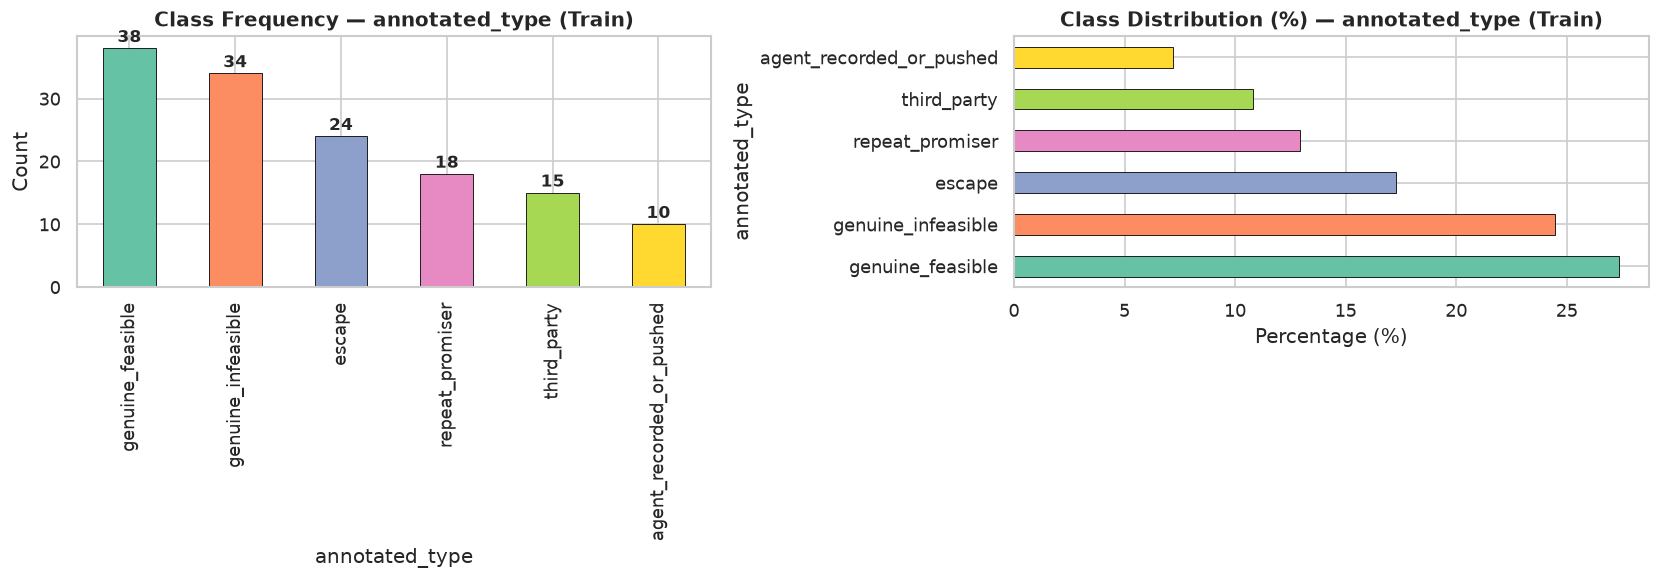

In [286]:
print("=" * 60)
print("CLASS DISTRIBUTION (Train Split Only)")
print("=" * 60)
display(class_table)
print(f"\nMajority class: {freq.idxmax()} ({freq.max()})")
print(f"Minority class: {freq.idxmin()} ({freq.min()})")
print(f"Overall IR (max/min): {freq.max() / freq.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette("Set2", n_colors=len(freq))
freq.plot.bar(ax=axes[0], color=colors, edgecolor="black", linewidth=0.5)
axes[0].set_title("Class Frequency — annotated_type (Train)", fontweight="bold")
axes[0].set_ylabel("Count")
for i, v in enumerate(freq.values):
    axes[0].text(i, v + 1, str(v), ha="center", fontweight="bold", fontsize=10)
pct.plot.barh(ax=axes[1], color=colors, edgecolor="black", linewidth=0.5)
axes[1].set_title("Class Distribution (%) — annotated_type (Train)", fontweight="bold")
axes[1].set_xlabel("Percentage (%)")
plt.tight_layout()
plt.show()


### 2.2 Mathematical Imbalance Metrics (Shannon Entropy & Gini Impurity)
Beyond simple percentages, we utilize information theory metrics to formally quantify the dataset's target imbalance. 
* **Shannon Entropy ($H$)** measures the unpredictability of the class distribution. A normalized entropy significantly below 1.0 indicates severe imbalance, dictating our downstream choices for evaluation metrics (Precision-Recall AUC over Accuracy) and class weighting strategies.

In [287]:
probs = pct.values / 100
k = len(probs)

shannon_H = entropy(probs, base=2)
max_H = np.log2(k)
normalised_H = shannon_H / max_H
effective_k = 2 ** shannon_H
gini_impurity = 1 - np.sum(probs**2)

print("=" * 50)
print("MATHEMATICAL IMBALANCE METRICS")
print("=" * 50)
print(f"Number of classes (k)       : {k}")
print(f"Shannon entropy H           : {shannon_H:.4f} bits")
print(f"Max entropy (uniform)       : {max_H:.4f} bits")
print(f"Normalised entropy (H/Hmax) : {normalised_H:.4f}  (1.0 = perfect balance)")
print(f"Effective #classes (2^H)    : {effective_k:.2f} out of {k}")
print(f"Gini impurity               : {gini_impurity:.4f}")

if normalised_H > 0.9:
    print("\n→ Distribution is fairly balanced.")
elif normalised_H > 0.7:
    print("\n→ Mild imbalance — confidence weighting is prudent.")
else:
    print("\n→ Significant imbalance — re-sampling or class weights needed.")

MATHEMATICAL IMBALANCE METRICS
Number of classes (k)       : 6
Shannon entropy H           : 2.4476 bits
Max entropy (uniform)       : 2.5850 bits
Normalised entropy (H/Hmax) : 0.9469  (1.0 = perfect balance)
Effective #classes (2^H)    : 5.46 out of 6
Gini impurity               : 0.8020

→ Distribution is fairly balanced.


### 2.3 Annotator Confidence Cross-Reference
Human annotations are inherently noisy. We evaluate the reliability of the labels by cross-referencing `annotated_type` against `annotator_confidence`. We use Chi-Square tests and Cramér's V to measure the association strength, identifying segments where label noise might degrade model performance.

CROSSTAB: annotated_type x annotator_confidence


annotator_confidence,high,low,medium
annotated_type,,,
agent_recorded_or_pushed,5,0,5
escape,14,2,8
genuine_feasible,24,2,12
genuine_infeasible,15,3,16
repeat_promiser,6,1,11
third_party,12,1,2



Chi-Square: 12.1515,  p-value: 0.275043,  Cramér's V: 0.2091


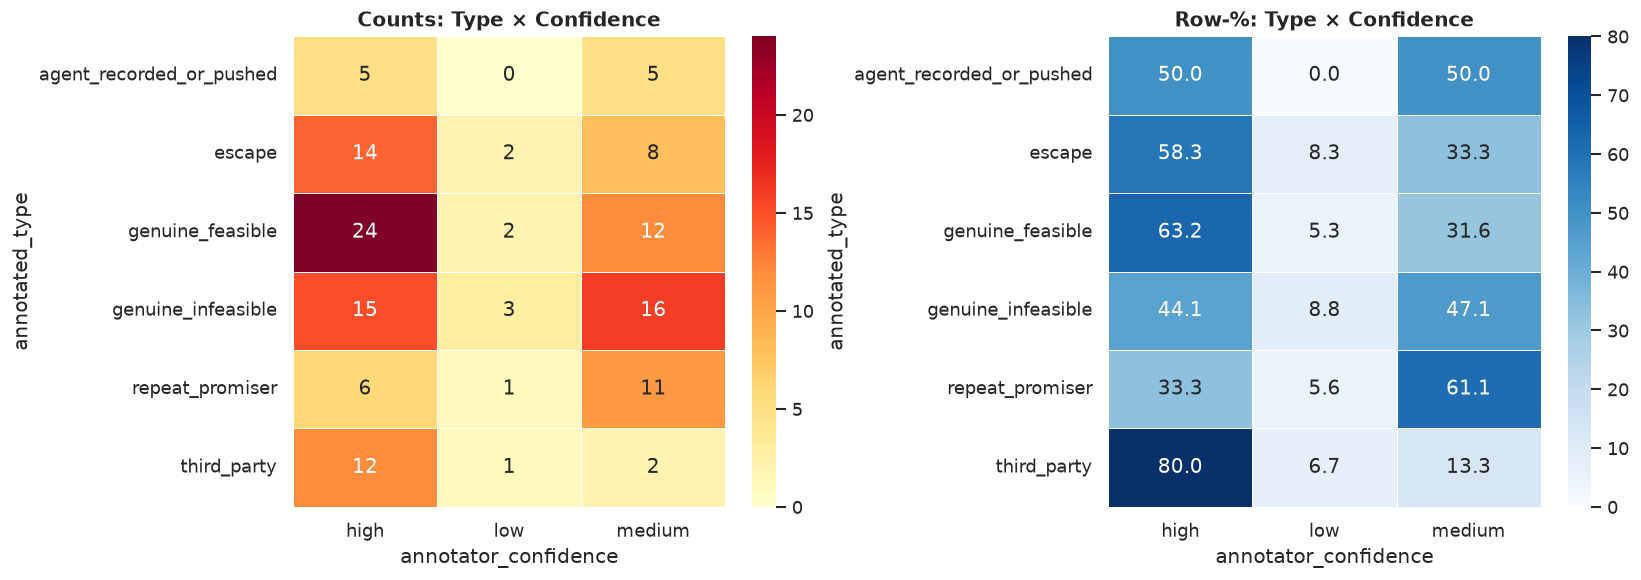

In [288]:
ct_counts = pd.crosstab(train_df["annotated_type"], train_df["annotator_confidence"])
ct_pct = pd.crosstab(train_df["annotated_type"], train_df["annotator_confidence"], normalize="index") * 100

chi2_conf, p_conf, dof_conf, _ = chi2_contingency(ct_counts)
n_total_conf = ct_counts.sum().sum()
cramers_v_conf = np.sqrt(chi2_conf / (n_total_conf * (min(ct_counts.shape) - 1)))

print("=" * 60)
print("CROSSTAB: annotated_type x annotator_confidence")
print("=" * 60)
display(ct_counts)
print(f"\nChi-Square: {chi2_conf:.4f},  p-value: {p_conf:.6f},  Cramér's V: {cramers_v_conf:.4f}")
if p_conf < 0.05:
    print("→ Significant association (p < 0.05): PTP type and confidence are NOT independent.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(ct_counts, annot=True, fmt="d", cmap="YlOrRd", ax=axes[0], linewidths=0.5)
axes[0].set_title("Counts: Type × Confidence", fontweight="bold")
sns.heatmap(ct_pct, annot=True, fmt=".1f", cmap="Blues", ax=axes[1], linewidths=0.5)
axes[1].set_title("Row-%: Type × Confidence", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.4 Flag Unreliable Entries
Based on the confidence assessment, we proactively flag entries with "low" annotator confidence. This allows the model to potentially down-weight these uncertain records during the training phase, improving overall robustness.

In [289]:
master_df["is_unreliable_label"] = (master_df["annotator_confidence"] == "low").astype(int)
unreliable = train_df[train_df["annotator_confidence"] == "low"]
print(f"Low-confidence entries in train: {len(unreliable)} / {len(train_df)} "
      f"({len(unreliable)/len(train_df)*100:.1f}%)")
if "low" in ct_pct.columns:
    print("\nShare of low-confidence per class:")
    display(ct_pct["low"].sort_values(ascending=False).to_frame("% low-confidence").round(1))

Low-confidence entries in train: 9 / 2572 (0.3%)

Share of low-confidence per class:


,% low-confidence
annotated_type,
genuine_infeasible,8.8
escape,8.3
third_party,6.7
repeat_promiser,5.6
genuine_feasible,5.3
agent_recorded_or_pushed,0.0


### 2.5 Univariate Analysis — Continuous Variables
We inspect the statistical distributions of our continuous variables (e.g., call durations, propensity scores). This helps identify skewness, zero-inflation, and extreme outliers that may require non-linear transformations or robust scaling prior to modeling.

In [290]:
continuous_cols = ["talk_duration_s", "ring_duration_s", "selection_propensity", "turn_count"]
existing_cont = [c for c in continuous_cols if c in train_df.columns]

print("=" * 60)
print("DESCRIPTIVE STATISTICS — CONTINUOUS VARIABLES (Train)")
print("=" * 60)
desc = train_df[existing_cont].describe().T
desc["skewness"] = train_df[existing_cont].skew()
desc["kurtosis"] = train_df[existing_cont].kurtosis()
desc["IQR"] = desc["75%"] - desc["25%"]
desc["CV (%)"] = (desc["std"] / desc["mean"] * 100).round(2)
display(desc.round(3))


DESCRIPTIVE STATISTICS — CONTINUOUS VARIABLES (Train)


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,IQR,CV (%)
talk_duration_s,2147.0,43.563,13.802,0.00,33.0,43.0,53.0,91.0,0.108,0.170,20.0,31.68
ring_duration_s,2147.0,11.763,5.522,2.00,7.0,12.0,16.0,43.0,0.473,0.906,9.0,46.94
selection_propensity,2147.0,0.980,0.106,0.25,1.0,1.0,1.0,1.0,-5.287,26.805,0.0,10.82


### Normality Testing (Shapiro-Wilk)
We systematically test our continuous distributions against the Gaussian assumption using the Shapiro-Wilk test to guide our choice of non-parametric correlation metrics.

In [291]:
# Shapiro-Wilk normality tests
print("\nShapiro-Wilk Normality Tests:")
for col in existing_cont:
    data = train_df[col].dropna()
    if len(data) > 5000:
        data = data.sample(5000, random_state=42)
    stat_sw, p_sw = stats.shapiro(data)
    print(f"  {col}: W={stat_sw:.4f}, p={p_sw:.6f} → {'Normal' if p_sw >= 0.05 else 'Non-Normal'}")



Shapiro-Wilk Normality Tests:
  talk_duration_s: W=0.9904, p=0.000000 → Non-Normal
  ring_duration_s: W=0.9450, p=0.000000 → Non-Normal
  selection_propensity: W=0.1797, p=0.000000 → Non-Normal


### Visualizing Continuous Distributions
We plot histograms overlaid with Kernel Density Estimates (KDE) to visually inspect long tails, bi-modal distributions, and skewness across behavioral indicators.

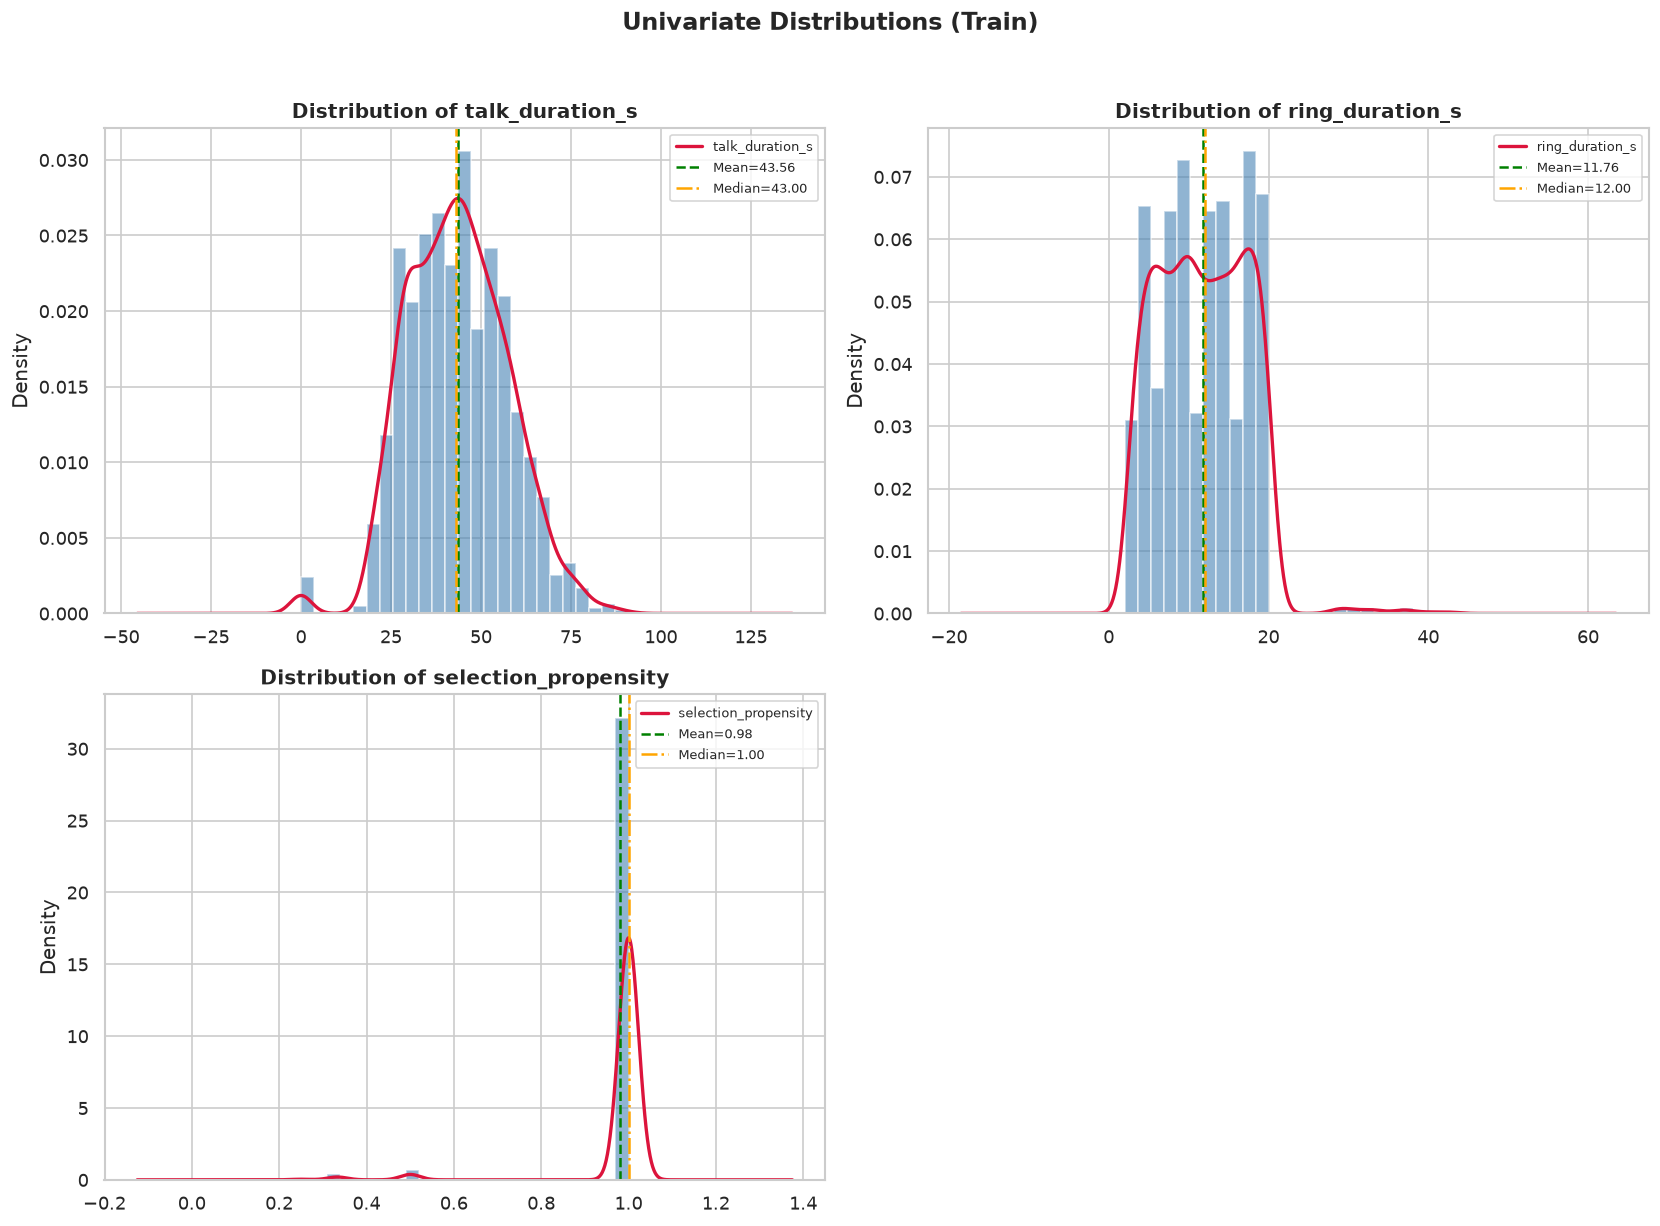

In [292]:
# Histograms with KDE
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(existing_cont):
    ax = axes[i]
    data = train_df[col].dropna()
    ax.hist(data, bins=25, density=True, alpha=0.6, color="steelblue", edgecolor="white")
    if data.nunique() > 2:
        data.plot.kde(ax=ax, color="crimson", linewidth=2)
    ax.axvline(data.mean(), color="green", ls="--", label=f"Mean={data.mean():.2f}")
    ax.axvline(data.median(), color="orange", ls="-.", label=f"Median={data.median():.2f}")
    ax.set_title(f"Distribution of {col}", fontweight="bold")
    ax.legend(fontsize=8)
for j in range(len(existing_cont), len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Univariate Distributions (Train)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 2.6 Univariate Analysis — Categorical Variables
Similarly, we evaluate the variance and cardinality of categorical features (e.g., portfolios, channels). Features with near-zero variance or overly high cardinality are flagged for appropriate encoding strategies (e.g., target encoding vs. one-hot encoding).

In [293]:
cat_cols = ["portfolio", "income_type", "lender_type", "channel", "hangup_by",
            "ptp_initiative", "disposition", "is_conditional", "discrepancy_flag", "log_integrity"]
existing_cat = [c for c in cat_cols if c in train_df.columns]

print("=" * 60)
print("FREQUENCY TABLES — CATEGORICAL VARIABLES (Train)")
print("=" * 60)
for col in existing_cat:
    vc = train_df[col].value_counts()
    pct_col = (vc / vc.sum() * 100).round(1)
    tbl = pd.DataFrame({"Count": vc, "%": pct_col})
    print(f"\n— {col} ({train_df[col].nunique()} categories) —")
    display(tbl)

FREQUENCY TABLES — CATEGORICAL VARIABLES (Train)

— portfolio (6 categories) —


,Count,%
portfolio,,
pl_salaried,721,28.0
two_wheeler,514,20.0
mfi_jlg,431,16.8
consumer_durable,319,12.4
credit_card,304,11.8
msme,283,11.0



— income_type (3 categories) —


,Count,%
income_type,,
salaried,1339,52.1
self_employed,856,33.3
daily_wage,377,14.7



— lender_type (6 categories) —


...

,Count,%
channel,,
tele_agent,1960,76.2
field,425,16.5
voice_bot,187,7.3



— hangup_by (3 categories) —


,Count,%
hangup_by,,
agent,1175,54.7
customer,955,44.5
network,17,0.8



— disposition (2 categories) —


,Count,%
disposition,,
rpc_ptp,2042,95.1
third_party_ptp,105,4.9


### 2.7 Bivariate Analysis: Kruskal-Wallis H-test (Target vs. Continuous)
To determine if continuous features have statistically significant predictive power distinguishing between PTP classes, we employ the Kruskal-Wallis H-test. We choose this non-parametric method because behavioral variables (like call durations) heavily violate standard normality assumptions.

In [294]:
print("=" * 60)
print("KRUSKAL-WALLIS H-TEST: annotated_type vs continuous vars")
print("=" * 60)

kw_results = []
for col in existing_cont:
    groups = [grp[col].dropna().values for _, grp in train_df.groupby("annotated_type")]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) >= 2:
        stat, p = kruskal(*groups)
        n_obs = sum(len(g) for g in groups)
        k_g = len(groups)
        eta2 = (stat - k_g + 1) / (n_obs - k_g) if n_obs > k_g else np.nan
        kw_results.append({"Variable": col, "H-statistic": round(stat, 4),
                           "p-value": round(p, 6), "eta_sq": round(eta2, 4),
                           "Significant": "Yes" if p < 0.05 else "No"})
display(pd.DataFrame(kw_results))


KRUSKAL-WALLIS H-TEST: annotated_type vs continuous vars


,Variable,H-statistic,p-value,eta_sq,Significant
0,talk_duration_s,37.1390,0.000001,0.2416,Yes
1,ring_duration_s,9.3747,0.095019,0.0329,No
2,selection_propensity,2.8386,0.724850,-0.0163,No


### Violin Plots for Continuous Target Separation
We visualize the non-parametric statistical separation found by the Kruskal-Wallis test using violin plots, which capture both density and summary statistics across promise categories.

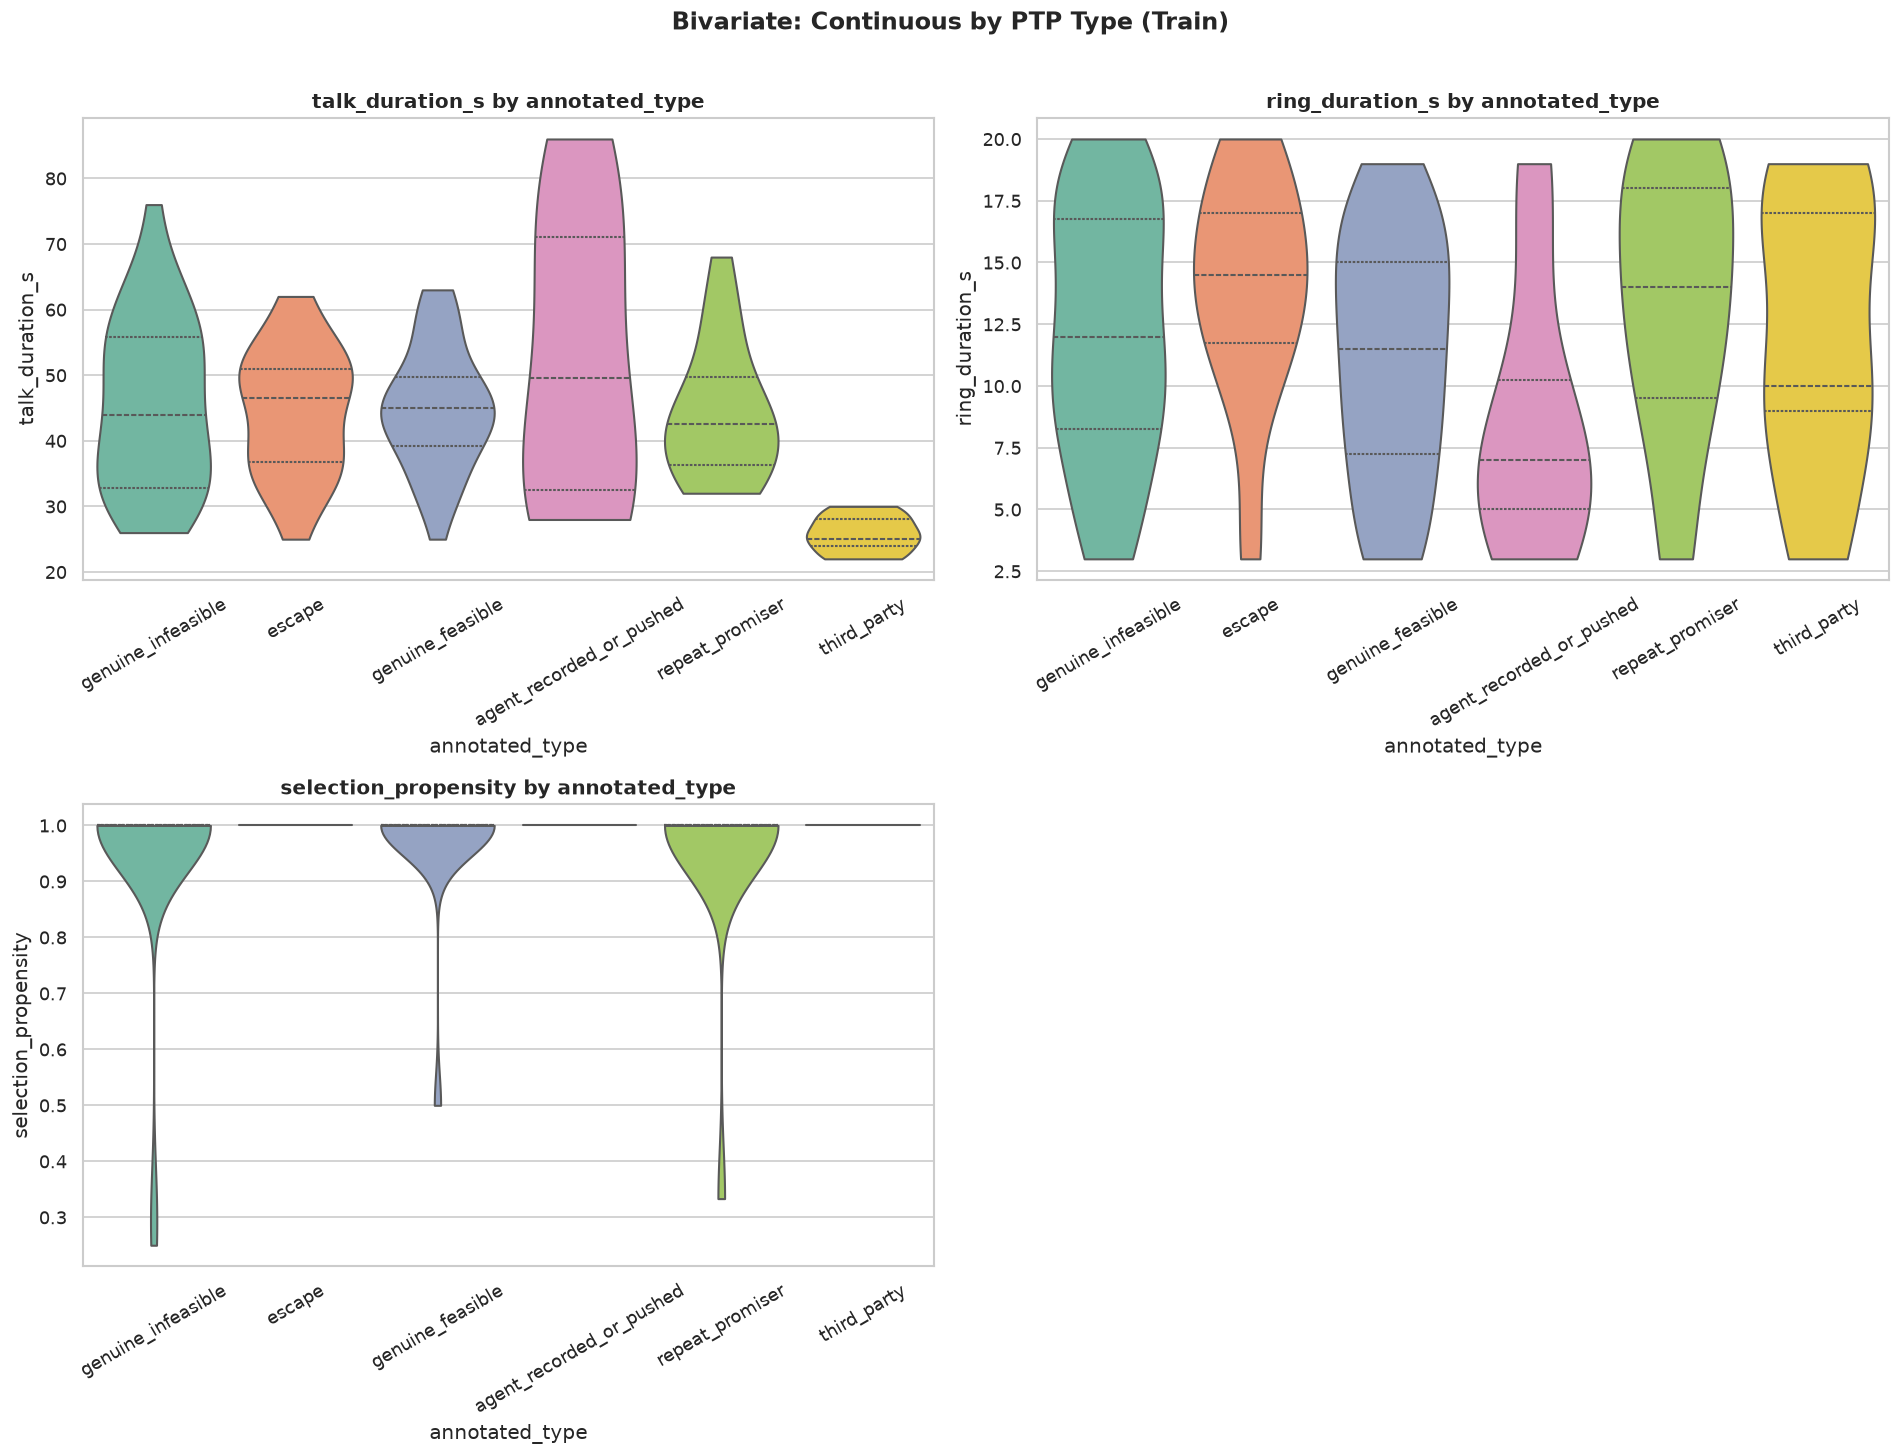

In [295]:
# Violin plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(existing_cont):
    sns.violinplot(data=train_df, x="annotated_type", y=col, ax=axes[i],
                   palette="Set2", inner="quartile", cut=0)
    axes[i].set_title(f"{col} by annotated_type", fontweight="bold")
    axes[i].tick_params(axis="x", rotation=30)
for j in range(len(existing_cont), len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Bivariate: Continuous by PTP Type (Train)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


### 2.8 Portfolio Bias & Lender Type Bias
We investigate systemic biases across different financial products. Certain loan portfolios or lender types inherently attract higher rates of fake promises due to the underlying risk profile of the borrowers. Identifying these biases informs demographic feature engineering.

PORTFOLIO BIAS: annotated_type x portfolio


portfolio,consumer_durable,credit_card,mfi_jlg,msme,pl_salaried,two_wheeler
annotated_type,,,,,,
agent_recorded_or_pushed,3,1,2,2,2,0
escape,6,4,1,2,7,4
genuine_feasible,3,3,5,6,17,4
genuine_infeasible,5,3,8,5,8,5
repeat_promiser,2,1,5,4,3,3
third_party,1,4,6,2,1,1



Chi-sq = 29.8533,  p = 0.229831,  Cramér's V = 0.2073


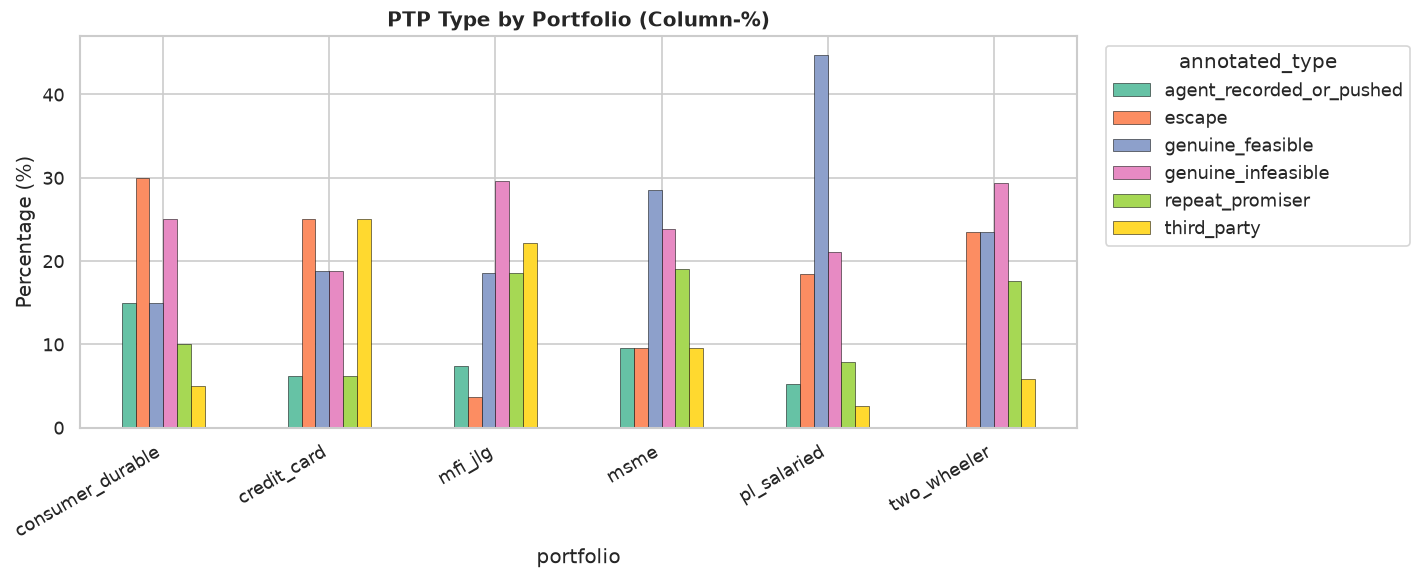

In [296]:
# Portfolio Bias
if "portfolio" in train_df.columns:
    ct_port = pd.crosstab(train_df["annotated_type"], train_df["portfolio"])
    ct_port_pct = pd.crosstab(train_df["annotated_type"], train_df["portfolio"], normalize="columns") * 100
    chi2_p, p_p, _, _ = chi2_contingency(ct_port)
    v_p = np.sqrt(chi2_p / (ct_port.sum().sum() * (min(ct_port.shape) - 1)))
    print("=" * 60)
    print("PORTFOLIO BIAS: annotated_type x portfolio")
    print("=" * 60)
    display(ct_port)
    print(f"\nChi-sq = {chi2_p:.4f},  p = {p_p:.6f},  Cramér's V = {v_p:.4f}")
    ct_port_pct.T.plot.bar(figsize=(12, 5), edgecolor="black", linewidth=0.3)
    plt.title("PTP Type by Portfolio (Column-%)", fontweight="bold")
    plt.ylabel("Percentage (%)")
    plt.legend(title="annotated_type", bbox_to_anchor=(1.02, 1))
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


### Validating Lender Type Bias
We repeat the bias analysis for specific `lender_type` entities (e.g., Payday lenders vs. Auto loans) using heatmap representations of Cramér's V associations.


LENDER TYPE BIAS: annotated_type x lender_type


lender_type,Fintech NBFC,NBFC,NBFC (MSME),NBFC-MFI,Private bank,Small finance bank
annotated_type,,,,,,
agent_recorded_or_pushed,1,2,1,1,3,2
escape,8,5,0,1,7,3
genuine_feasible,11,3,2,1,11,10
genuine_infeasible,7,3,3,5,8,8
repeat_promiser,4,2,1,3,2,6
third_party,0,2,0,3,5,5


Chi-sq = 23.1683,  p = 0.567738,  Cramér's V = 0.1826


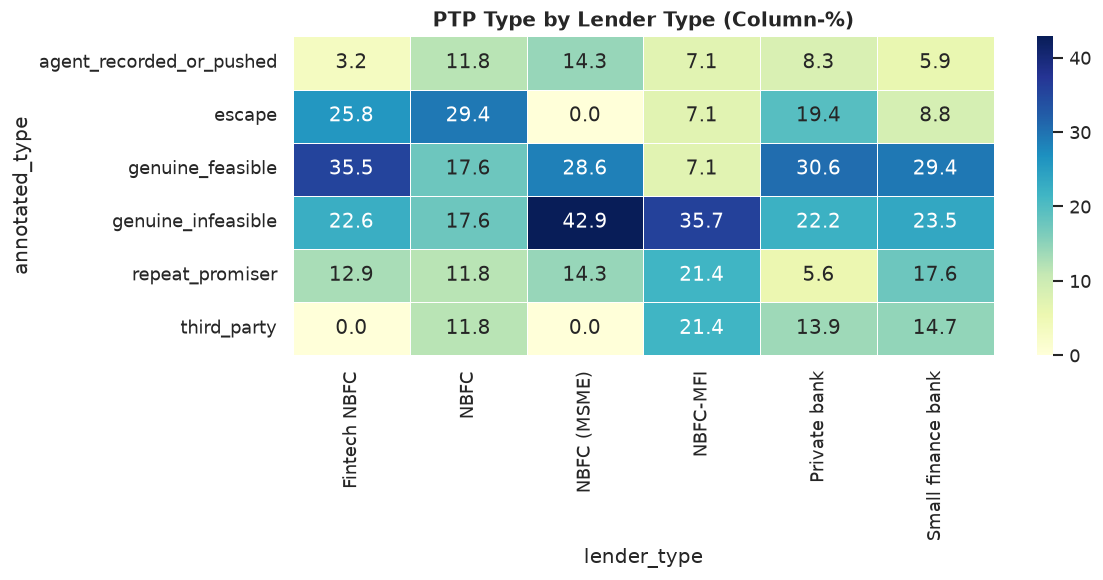

In [297]:
# Lender Type Bias
if "lender_type" in train_df.columns:
    ct_lend = pd.crosstab(train_df["annotated_type"], train_df["lender_type"])
    ct_lend_pct = pd.crosstab(train_df["annotated_type"], train_df["lender_type"], normalize="columns") * 100
    chi2_l, p_l, _, _ = chi2_contingency(ct_lend)
    v_l = np.sqrt(chi2_l / (ct_lend.sum().sum() * (min(ct_lend.shape) - 1)))
    print("\n" + "=" * 60)
    print("LENDER TYPE BIAS: annotated_type x lender_type")
    print("=" * 60)
    display(ct_lend)
    print(f"Chi-sq = {chi2_l:.4f},  p = {p_l:.6f},  Cramér's V = {v_l:.4f}")
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.heatmap(ct_lend_pct, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, ax=ax)
    ax.set_title("PTP Type by Lender Type (Column-%)", fontweight="bold")
    plt.tight_layout()
    plt.show()


### 2.9 Ground Truth vs. Human Perception (`is_kept` Keep Rates)
We compare the human-annotated labels (`annotated_type`) against the empirically calculated ground truth (`is_kept`). This validates whether human intuition about "fake" vs "real" promises actually aligns with subsequent financial reality.

TARGET VALIDATION: annotated_type x is_kept


is_kept,0,1
annotated_type,,
agent_recorded_or_pushed,90.0,10.0
escape,100.0,0.0
genuine_feasible,42.1,57.9
genuine_infeasible,88.2,11.8
repeat_promiser,100.0,0.0
third_party,66.7,33.3



Chi-sq = 42.9260,  p = 0.000000,  Cramér's V = 0.5557


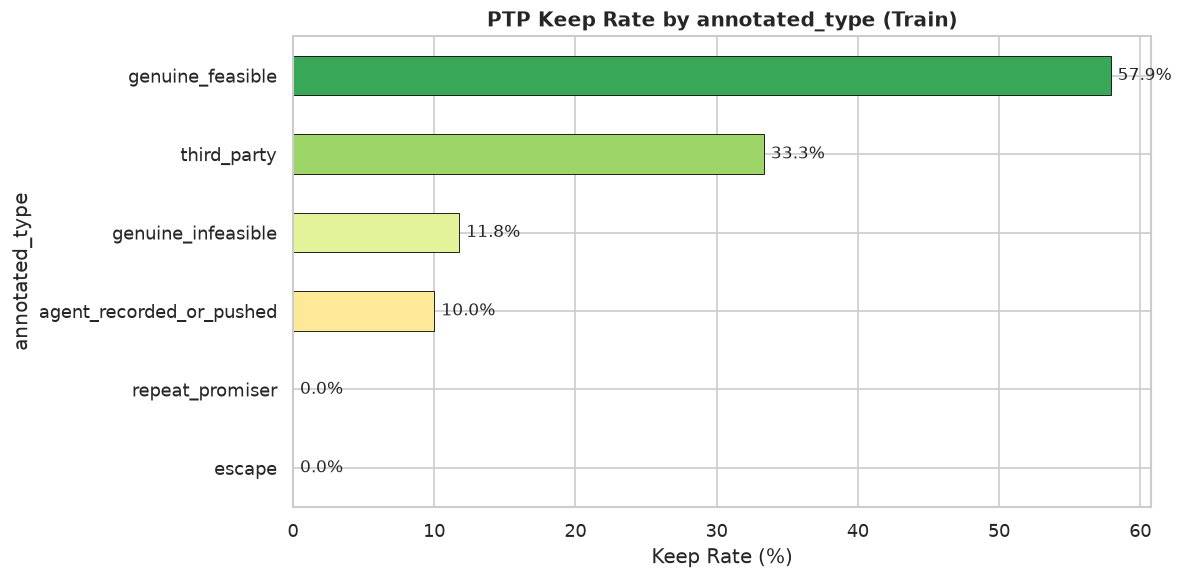

In [298]:
ct_kept = pd.crosstab(train_df["annotated_type"], train_df["is_kept"])
ct_kept_pct = pd.crosstab(train_df["annotated_type"], train_df["is_kept"], normalize="index") * 100
chi2_k, p_k, _, _ = chi2_contingency(ct_kept)
v_k = np.sqrt(chi2_k / (ct_kept.sum().sum() * (min(ct_kept.shape) - 1)))
print("=" * 60)
print("TARGET VALIDATION: annotated_type x is_kept")
print("=" * 60)
display(ct_kept_pct.round(1))
print(f"\nChi-sq = {chi2_k:.4f},  p = {p_k:.6f},  Cramér's V = {v_k:.4f}")

keep_col = 1 if 1 in ct_kept_pct.columns else ct_kept_pct.columns[-1]
keep_rate = ct_kept_pct[keep_col].sort_values()
ax = keep_rate.plot.barh(figsize=(10, 5), color=sns.color_palette("RdYlGn", len(keep_rate)),
                         edgecolor="black", linewidth=0.5)
ax.set_xlabel("Keep Rate (%)")
ax.set_title("PTP Keep Rate by annotated_type (Train)", fontweight="bold")
for i, v in enumerate(keep_rate.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=10)
plt.tight_layout()
plt.show()

### 2.10 Summary Chi-Square Tests Across All Categoricals
We perform bulk Chi-Square tests of independence across all categorical predictors against the target. This systematic filtering identifies the subset of categorical variables that hold statistically significant signal, guiding our feature selection process.

In [299]:
chi_results = []
test_cats = ["portfolio", "income_type", "lender_type", "channel", "hangup_by",
             "ptp_initiative", "is_conditional", "discrepancy_flag", "log_integrity"]
for col in test_cats:
    if col in train_df.columns:
        ct = pd.crosstab(train_df["annotated_type"], train_df[col])
        if ct.shape[0] >= 2 and ct.shape[1] >= 2:
            c2, p, dof_c, _ = chi2_contingency(ct)
            v = np.sqrt(c2 / (ct.sum().sum() * (min(ct.shape) - 1)))
            chi_results.append({"Variable": col, "Chi-sq": round(c2, 2), "p-value": round(p, 6),
                                "dof": dof_c, "Cramér's V": round(v, 4),
                                "Significant": "Yes" if p < 0.05 else "No"})
display(pd.DataFrame(chi_results))

,Variable,Chi-sq,p-value,dof,Cramér's V,Significant
0,portfolio,29.85,0.229831,25,0.2073,No
1,income_type,20.76,0.022801,10,0.2733,Yes
2,lender_type,23.17,0.567738,25,0.1826,No
3,channel,3.82,0.575179,5,0.1658,No
4,hangup_by,2.68,0.748996,5,0.1389,No


### 2.11 Spearman Rank Correlation Matrix
We compute a Spearman correlation matrix among numerical features to check for multicollinearity. Spearman (rank-based) is preferred over Pearson as it is robust to outliers and captures monotonic, non-linear relationships.

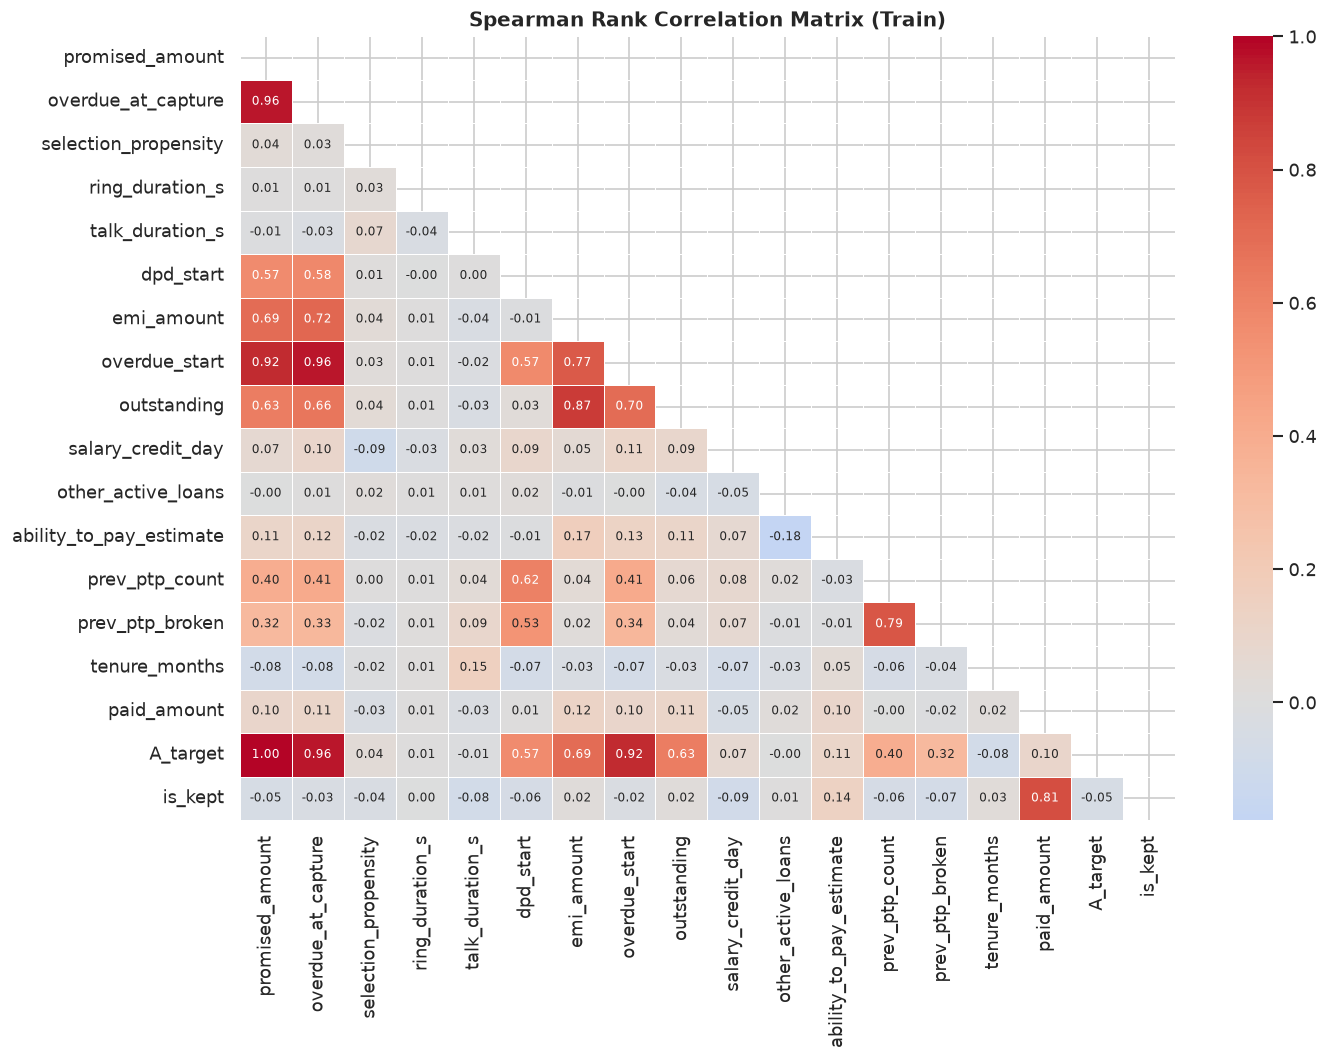

In [300]:
num_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
corr_spearman = train_df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=ax, annot_kws={"size": 7})
ax.set_title("Spearman Rank Correlation Matrix (Train)", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.12 Feature Engineering: Confidence Weights & One-Hot Encoding
We engineer our first set of features based on the univariate and bivariate insights. We map confidence levels to numeric weights (`confidence_weight`) and create one-hot encoded representations for statistically significant categorical variables like `lender_type`.

In [301]:
# confidence_weight: high=1.0, medium=0.7, low=0.3
conf_map = {"high": 1.0, "medium": 0.7, "low": 0.3}
master_df["confidence_weight"] = master_df["annotator_confidence"].str.lower().map(conf_map).fillna(1.0)

# One-hot encode lender_type
if "lender_type" in master_df.columns:
    dummies = pd.get_dummies(master_df["lender_type"], prefix="lender", dtype=int)
    master_df = pd.concat([master_df, dummies], axis=1)

    # Verify row sums
    lender_ohe = [c for c in master_df.columns if c.startswith("lender_") and c != "lender_type" and c != "lender_id" and c != "lender_name"]
    row_sums = master_df[lender_ohe].sum(axis=1).unique()
    print(f"One-hot lender columns: {lender_ohe}")
    print(f"Row sums (should all be 1): {row_sums}")


One-hot lender columns: ['lender_Fintech NBFC', 'lender_NBFC', 'lender_NBFC (MSME)', 'lender_NBFC-MFI', 'lender_Private bank', 'lender_Small finance bank']
Row sums (should all be 1): [1]


### Computing Effective Sample Size (Kish's Formula)
After applying confidence weights, we must verify our remaining statistical power. We calculate Kish's Effective Sample Size to ensure down-weighting noisy labels hasn't destroyed class representation.

In [302]:
# Kish's effective sample size
print("\nEffective Sample Size After Confidence Weighting:")
eff_rows = []
for cls in sorted(train_df["annotated_type"].dropna().unique()):
    mask_cls = (master_df["split"] == "train") & (master_df["annotated_type"] == cls)
    w = master_df.loc[mask_cls, "confidence_weight"]
    n_raw = len(w)
    n_eff = (w.sum() ** 2) / (w**2).sum() if (w**2).sum() > 0 else 0
    eff_rows.append({"annotated_type": cls, "n_raw": n_raw,
                     "n_eff_kish": round(n_eff, 1), "retention_%": round(n_eff / n_raw * 100, 1)})
display(pd.DataFrame(eff_rows).set_index("annotated_type"))

print("\nTM1 Features Built: confidence_weight, is_unreliable_label, lender_*")



Effective Sample Size After Confidence Weighting:


,n_raw,n_eff_kish,retention_%
annotated_type,,,
agent_recorded_or_pushed,10,9.7,97.0
escape,24,22.5,93.9
genuine_feasible,38,36.2,95.3
genuine_infeasible,34,31.8,93.5
repeat_promiser,18,17.1,94.9
third_party,15,14.4,95.7



TM1 Features Built: confidence_weight, is_unreliable_label, lender_*


## 3. Agent Behavior & Channel Dynamics
### 3.1 Channel Segmentation: Bot vs. Human Dynamics
The medium of interaction heavily influences collection outcomes. We segment interactions by channel, specifically creating an `is_bot` flag, to isolate the differing promise-keeping dynamics between automated voice bots and human collection agents.

In [303]:
master_df["is_bot"] = (master_df["channel"] == "voice_bot").astype(int)
print("Channel Split:")
print(master_df["channel"].value_counts())

Channel Split:
channel
tele_agent    2841
field          605
voice_bot      250
Name: count, dtype: int64


### 3.2 Shift Bunching Flag (Agent Fatigue Hypothesis)
We hypothesize that collection agents exhibit different behaviors near the end of their shifts (e.g., rushing calls to meet quotas, leading to lower-quality PTPs). We engineer a time-of-day feature and flag calls that occur in late-shift hours.

In [304]:
master_df["tod_min"] = master_df["captured_ts"].dt.hour * 60 + master_df["captured_ts"].dt.minute
human_mask = master_df["is_bot"] == 0
shift_end = int(np.ceil(master_df.loc[human_mask, "tod_min"].quantile(0.999) / 60) * 60)

master_df["shift_bunching_flag"] = (human_mask & (master_df["tod_min"] >= shift_end - 30)).astype(int)

# Validate: is the last 30 min really busier?
last30 = human_mask & (master_df["tod_min"] >= shift_end - 30)
prev2h = human_mask & (master_df["tod_min"] >= shift_end - 150) & (master_df["tod_min"] < shift_end - 30)
print(f"Inferred Shift End: {shift_end // 60}:00")
print(f"PTPs/min in last 30 min: {last30.sum() / 30:.2f} | previous 2h: {prev2h.sum() / 120:.2f}")
print(f"Flagged: {master_df['shift_bunching_flag'].sum()} of {human_mask.sum()} human PTPs")

Inferred Shift End: 19:00
PTPs/min in last 30 min: 2.67 | previous 2h: 2.11
Flagged: 80 of 3446 human PTPs


### 3.3 Language Team Target Encoding
Different regional language desks may experience varying baseline rates of broken promises due to macro-economic or cultural factors. We apply smoothed target encoding to the language team variable, ensuring we only fit the encoding on the training split to prevent data leakage.

In [305]:
# Refresh train_df to include is_kept
train_df = master_df[master_df["split"] == "train"].copy()

if "language_team" in train_df.columns:
    lang_keep_rates = train_df.groupby("language_team")["is_kept"].mean().to_dict()
    global_mean = train_df["is_kept"].mean()
    master_df["language_team_encoded"] = master_df["language_team"].map(lang_keep_rates).fillna(global_mean)
    print("Target Encoded Language Teams (fitted on train):")
    for k, v in lang_keep_rates.items():
        print(f"  {k}: {v:.3f} keep rate")

Target Encoded Language Teams (fitted on train):
  all: 0.305 keep rate
  english: 0.262 keep rate
  hinglish: 0.284 keep rate
  kanglish: 0.299 keep rate


### 3.4 Agent Tenure vs. Fake Promise Labels
Does agent experience mitigate fake promises? We analyze the relationship between agent tenure and the prevalence of fake PTPs, aiming to uncover if seasoned agents are better at securing genuine commitments.

In [306]:
# Refresh train_df again
train_df = master_df[master_df["split"] == "train"].copy()

h = train_df[(train_df["is_bot"] == 0) & train_df["annotated_type"].notna()].copy()
h["borrower_escape"] = (h["annotated_type"] == "escape").astype(int)
h["agent_pushed"] = (h["annotated_type"] == "agent_recorded_or_pushed").astype(int)
h["any_flag"] = h[["borrower_escape", "agent_pushed"]].max(axis=1)
h["tenure_months"] = pd.to_numeric(h["tenure_months"], errors="coerce")

ag = h.groupby("agent_id").agg(
    n=("any_flag", "size"), k=("any_flag", "sum"),
    pushed=("agent_pushed", "sum"), tenure=("tenure_months", "first")
).reset_index()
ag["rate"] = ag["k"] / ag["n"]
ag["lo"], ag["hi"] = zip(*[wilson_ci(int(k), int(n)) for k, n in zip(ag["k"], ag["n"])])

rho, rho_p = stats.spearmanr(ag["tenure"].fillna(0), ag["rate"])


### Categorical Tenure Banding
In addition to continuous rank correlation, we discretize tenure into discrete bins (<=12m, 13-36m, >36m) to test for non-linear threshold effects via Chi-square.

In [307]:
h["tenure_band"] = pd.cut(h["tenure_months"], [0, 12, 36, 120], labels=["<=12m", "13-36m", ">36m"])
ct_band = pd.crosstab(h["tenure_band"], h["any_flag"])
band_p = chi2_contingency(ct_band)[1] if ct_band.shape[0] >= 2 and ct_band.shape[1] >= 2 else np.nan

print(f"Spearman (Tenure vs Fake Rate): rho = {rho:.2f}, p = {rho_p:.3f}")
print(f"Chi-square (Banded Tenure vs Fake Rate): p = {band_p:.3f}")
print(f"agent_recorded_or_pushed total: {int(h['agent_pushed'].sum())}\n")


Spearman (Tenure vs Fake Rate): rho = -0.28, p = 0.228
Chi-square (Banded Tenure vs Fake Rate): p = 0.351
agent_recorded_or_pushed total: 10



### Tenure Trend Visualization
We plot the Fake Promise Rate explicitly against Agent Tenure bands, applying Wilson 95% Confidence Intervals to ensure visual trends are statistically robust.

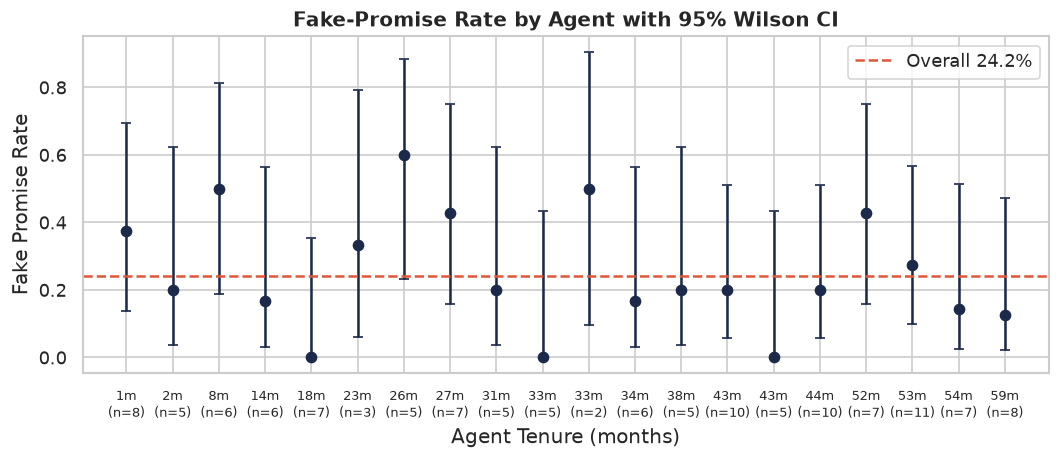

In [308]:
# Error bar plot
fig, ax = plt.subplots(figsize=(9, 4))
ag = ag.sort_values("tenure")
x = np.arange(len(ag))
ax.errorbar(x, ag["rate"], yerr=[(ag["rate"] - ag["lo"]).clip(lower=0), (ag["hi"] - ag["rate"]).clip(lower=0)],
            fmt="o", capsize=3, color=PRIMARY_NAVY)
ax.axhline(h["any_flag"].mean(), ls="--", color=ACCENT_CORAL,
           label=f"Overall {h['any_flag'].mean():.1%}")
ax.set_xticks(x)
ax.set_xticklabels([f"{t:.0f}m\n(n={n})" for t, n in zip(ag["tenure"], ag["n"])], fontsize=8)
ax.set_ylabel("Fake Promise Rate")
ax.set_xlabel("Agent Tenure (months)")
ax.set_title("Fake-Promise Rate by Agent with 95% Wilson CI", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Live Conversational Linguistics (NLP)
### 4.1 Text Normalization Pipeline
Conversational transcripts are a rich source of behavioral signal. We implement an NLP normalization pipeline—lowercasing text, stripping punctuation, and handling missing values—to prepare the transcripts for reliable feature extraction.

In [309]:
transcripts = transcripts_raw.copy()
transcripts["text"] = transcripts["text"].fillna("")

# Full Devanagari normalization map
DEVANAGARI_MAP = {
    "देखता हूँ": "dekhta hoon", "कोशिश करूंगा": "koshish karunga", "शायद": "shayad",
    "सैलरी आएगी तो": "salary aayi toh", "पैसे आए तो": "paisa aaya toh", "कुछ दिन": "kuch din",
    "अगले हफ्ते": "agle hafte", "महीने के आखिर": "mahine ke end", "पक्का": "pakka",
    "पैसे नहीं हैं": "paise nahi hain", "नौकरी चली गई": "naukri chali gayi", "हाँ": "haan",
    "ठीक है": "theek hai", "दो हज़ार": "2000", "हज़ार": "hazaar", "कल": "kal", "परसों": "parso",
}
DEV_DIGITS = str.maketrans("०१२३४५६७८९", "0123456789")

_RE_TAGS = re.compile(r"\[(inaudible|name|lender)\]", re.I)
_RE_RUPEE = re.compile(r"(₹|rs\.?|inr)\s*", re.I)
_RE_PUNCT = re.compile(r"[^\w\s/-]")
_RE_REPEAT = re.compile(r"([^\d\s])\1{2,}")
_RE_WS = re.compile(r"\s+")

def normalize_text(text):
    t = str(text)
    for k, v in DEVANAGARI_MAP.items():
        if k in t:
            t = t.replace(k, v)
    t = t.translate(DEV_DIGITS).lower()
    t = _RE_TAGS.sub(" ", t)
    t = _RE_RUPEE.sub(" ", t)
    t = _RE_PUNCT.sub(" ", t)
    t = _RE_REPEAT.sub(r"\1\1", t)
    return _RE_WS.sub(" ", t).strip()


### Applying Normalization & Speaker Canonicalization
We map diverse speaker tags (bot, executive, caller) to canonical AGENT and BORROWER labels, and process the raw text through our normalization logic.

In [310]:
# Speaker canonicalization
transcripts["speaker_raw"] = transcripts["speaker"].astype(str).str.strip().str.lower()
transcripts["spk"] = transcripts["speaker_raw"].map(
    lambda s: "AGENT" if s in ["agent", "bot", "executive", "caller"] else "BORROWER"
)
transcripts["norm_text"] = [normalize_text(t) for t in transcripts["text"]]
transcripts = transcripts.sort_values(["call_id", "turn_idx"]).reset_index(drop=True)

print(f"Transcripts normalized: {len(transcripts):,} turns across {transcripts['call_id'].nunique():,} calls")
display(transcripts[["call_id", "spk", "norm_text"]].head(5))


Transcripts normalized: 39,194 turns across 3,367 calls


,call_id,spk,norm_text
0,AT0000018,AGENT,hello collections team se bol rahi hoon ji bol...
1,AT0000018,BORROWER,haan boliye
2,AT0000018,AGENT,aapke loan account mein 6 000 rupaye overdue h...
3,AT0000018,AGENT,pichli baar bhi aapne 29 january ka bola tha p...
4,AT0000018,BORROWER,woh baat thi is baar ho jayega


### 4.2 Code-Mixing Prevalence Audit (Hinglish/Multilingual)
Collection calls in certain regions frequently feature code-mixing (e.g., Hindi and English). We audit the transcripts for common mixed-language tokens to ensure our subsequent linguistic rulesets accommodate this linguistic reality.

In [311]:
hindi_tokens = {"haan", "ji", "theek", "kar", "dunga", "nahi", "hai", "koshish", "dekhta", "hoon",
                "paise", "salary", "aayi", "agle", "hafte", "kal", "parso", "aaj", "toh", "tak"}
english_tokens = {"yes", "no", "okay", "ok", "fine", "sure", "definitely", "confirm", "pay", "payment",
                  "tomorrow", "today", "next", "week", "month", "account", "problem", "salary", "money"}
kannada_tokens = {"haudu", "maadtini", "nodtini", "kodtini", "amele", "duddu", "illa", "kelsa", "tingalu", "bandre"}

# Only train-linked borrower turns
train_attempt_ids = set(train_df["attempt_id"].dropna().unique())
train_trans = transcripts[(transcripts["call_id"].isin(train_attempt_ids)) & (transcripts["spk"] == "BORROWER")]

mixed_count = 0
total_b_turns = len(train_trans)
for t in train_trans["norm_text"]:
    toks = set(t.split())
    has_hi = bool(toks & hindi_tokens)
    has_en = bool(toks & english_tokens)
    has_kn = bool(toks & kannada_tokens)
    if (has_hi and has_en) or (has_kn and has_en):
        mixed_count += 1

print(f"Code-Mixing Audit ({total_b_turns:,} Borrower Turns in Train):")
print(f"  Code-Mixed Turns (Hinglish/Kanglish): {mixed_count:,} ({mixed_count/max(total_b_turns,1)*100:.2f}%)")

Code-Mixing Audit (10,927 Borrower Turns in Train):
  Code-Mixed Turns (Hinglish/Kanglish): 1,379 (12.62%)


### 4.3 Linguistic Signals vs. Keep Rate (Hedges & Reluctance)
Borrowers intending to break a promise often use linguistic "hedges" (e.g., "I will try", "Let me see"). We extract the frequency of these specific phrases, hypothesizing a strong negative correlation between hedge usage and the probability of keeping the promise.

In [312]:
HEDGE_TERMS = [
    "dekhta hoon", "dekhti hoon", "dekhte hain", "dekhenge", "try karunga", "try karungi",
    "koshish karunga", "koshish karta hoon", "pata nahi", "shayad", "sochta hoon",
    "ho jayega", "kar dunga", "let me see", "i will try", "will try", "maybe", "if possible",
    "hopefully", "dekhna padega", "try maadtini", "nodona", "nodtini",
]
CONDITION_TERMS = [
    "salary aayi toh", "salary aane par", "salary aate hi", "paisa aaya toh",
    "agar", "jab paisa", "jaise hi", "koi dega toh", "bonus aaya toh",
    "once salary", "jab tak", "duddu bandre", "salary banda mele",
]
VAGUE_DATE_TERMS = [
    "next week", "agle hafte", "month end", "mahine ke end", "jaldi", "kuch din mein",
    "do teen din", "soon", "jald hi", "kal parso", "baad mein", "later", "thoda time",
    "mundina vara", "swalpa dina", "kuch din", "some days",
]
FIRM_TERMS = [
    "pakka", "pakka kar dunga", "guarantee", "definitely", "zaroor",
    "abhi bhej raha hoon", "upi se kar dunga", "aaj hi", "kal subah",
    "pakka kodtini", "definitely pay", "confirm maadtini", "poora kodtini",
    "zaroor karunga", "will definitely pay", "clear kar dunga",
]

# Build call lookup (call_id → list of turn rows)
calls_dict = defaultdict(list)
for row in transcripts.itertuples():
    calls_dict[row.call_id].append(row)

# Annotated type lookup
annotated_map = annotated_raw.set_index("ptp_id")["annotated_type"].to_dict()


### Extract Linguistic Signals from Transcripts
We iterate over the normalized borrower turns for each PTP in the training set and flag the presence of these defined linguistic patterns.

In [313]:
# Extract per-PTP signals for train uncensored
train_uncensored = train_df[train_df["is_kept"].notna()].copy()
records = []
for ptp in train_uncensored.itertuples():
    cid = ptp.attempt_id
    turns = [t for t in calls_dict.get(cid, []) if t.spk == "BORROWER"]
    all_b_text = " ".join([t.norm_text for t in turns])

    records.append({
        "ptp_id": ptp.ptp_id, "kept": ptp.is_kept,
        "has_hedge": any(h in all_b_text for h in HEDGE_TERMS),
        "has_condition": any(c in all_b_text for c in CONDITION_TERMS),
        "has_vague": any(v in all_b_text for v in VAGUE_DATE_TERMS),
        "has_firm": any(f in all_b_text for f in FIRM_TERMS),
    })

signals_df = pd.DataFrame(records)


### Statistical Validation of NLP Tokens
We compute the keep rate conditional on the presence of these linguistic features. We test for statistical significance using Chi-square and bounding the rates with Wilson CIs.

In [314]:
# Evaluate each signal with Wilson CIs and Chi-square
signal_names = [("Hesitation / Hedging", "has_hedge"), ("Conditional Language", "has_condition"),
                ("Vague Timing", "has_vague"), ("Strong Commitment", "has_firm")]

signal_summary = []
for display_name, col in signal_names:
    pres = signals_df[signals_df[col] == True]
    absn = signals_df[signals_df[col] == False]
    k_pres, n_pres = int(pres["kept"].sum()), len(pres)
    k_abs, n_abs = int(absn["kept"].sum()), len(absn)
    kr_pres = k_pres / n_pres if n_pres > 0 else 0
    kr_abs = k_abs / n_abs if n_abs > 0 else 0
    ci_pres = wilson_ci(k_pres, n_pres)
    ci_abs = wilson_ci(k_abs, n_abs)
    contingency = [[k_pres, n_pres - k_pres], [k_abs, n_abs - k_abs]]
    chi2_sig, p_sig, _, _ = chi2_contingency(contingency) if min(n_pres, n_abs) > 0 else (0, 1, 0, 0)
    signal_summary.append({
        "Signal": display_name, "n": n_pres, "Share (%)": f"{n_pres / len(signals_df) * 100:.1f}%",
        "Keep Rate (Present)": f"{kr_pres * 100:.1f}%", "95% CI": format_ci(ci_pres),
        "Keep Rate (Absent)": f"{kr_abs * 100:.1f}%", "Diff (pp)": f"{(kr_pres - kr_abs) * 100:+.1f}",
        "p-value": f"{p_sig:.4f}",
        "_kr_pres": kr_pres, "_kr_abs": kr_abs, "_ci_pres": ci_pres, "_ci_abs": ci_abs,
    })

display(pd.DataFrame(signal_summary)[["Signal", "n", "Share (%)", "Keep Rate (Present)", "95% CI",
                                        "Keep Rate (Absent)", "Diff (pp)", "p-value"]])


,Signal,n,Share (%),Keep Rate (Present),95% CI,Keep Rate (Absent),Diff (pp),p-value
0,Hesitation / Hedging,1268,49.3%,26.3%,"[24.0%, 28.8%]",30.4%,-4.1,0.0236
1,Conditional Language,160,6.2%,23.8%,"[17.8%, 30.9%]",28.7%,-5.0,0.2068
2,Vague Timing,760,29.5%,23.4%,"[20.5%, 26.6%]",30.5%,-7.1,0.0003
3,Strong Commitment,601,23.4%,45.9%,"[42.0%, 49.9%]",23.1%,+22.8,0.0000


### NLP Signal Impact Bar Charts
We graphically represent the delta in promise fulfillment when specific hesitation, condition, or firm commitment language is used during the call.

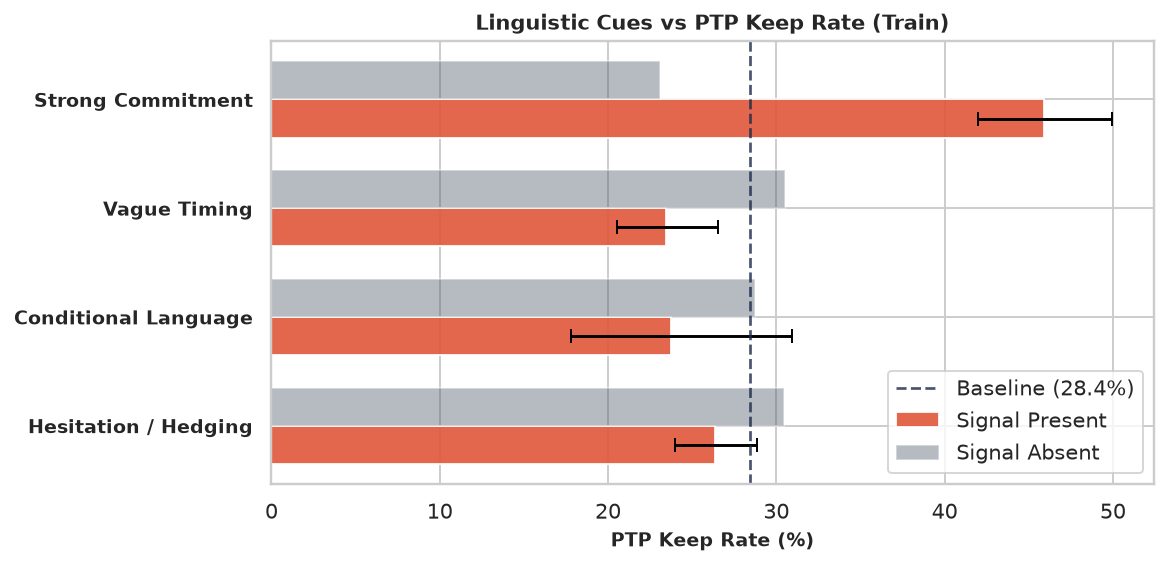

In [315]:
# Visualization
fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=140)
y_pos = np.arange(len(signal_summary))
bar_h = 0.35
kr_pres_vals = [s["_kr_pres"] * 100 for s in signal_summary]
kr_abs_vals = [s["_kr_abs"] * 100 for s in signal_summary]
err_pres = [[(s["_kr_pres"] - s["_ci_pres"][0]) * 100 for s in signal_summary],
            [(s["_ci_pres"][1] - s["_kr_pres"]) * 100 for s in signal_summary]]
ax.barh(y_pos - bar_h / 2, kr_pres_vals, bar_h, xerr=err_pres, color=ACCENT_CORAL, alpha=0.9,
        label="Signal Present", capsize=3.5)
ax.barh(y_pos + bar_h / 2, kr_abs_vals, bar_h, color="#4A5568", alpha=0.4, label="Signal Absent")
baseline_kr = train_uncensored["is_kept"].mean() * 100
ax.axvline(baseline_kr, color=PRIMARY_NAVY, ls="--", lw=1.4, alpha=0.8,
           label=f"Baseline ({baseline_kr:.1f}%)")
ax.set_yticks(y_pos)
ax.set_yticklabels([s["Signal"] for s in signal_summary], fontsize=10, fontweight="bold")
ax.set_xlabel("PTP Keep Rate (%)", fontsize=10, fontweight="bold")
ax.set_title("Linguistic Cues vs PTP Keep Rate (Train)", fontsize=11, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 4.4 Categorizing Linguistic Nuance: Uncertainty vs. Conditional
We refine our NLP features by distinguishing between explicit uncertainty (e.g., "I don't know") and conditional agreements (e.g., "If I get my salary"). Different categories of hesitation carry different predictive weights.

In [316]:
UNCERTAINTY_PHRASES = ["dekhta hoon", "dekhti hoon", "sochta hoon", "dekhna padega", "let me see", "pata nahi"]
SPECIFIC_CONDITIONS = ["salary aayi toh", "salary aane par", "bonus aaya toh", "paisa aaya toh",
                       "payment aane ke baad", "once salary"]

cat_records = []
for ptp in train_uncensored.itertuples():
    cid = ptp.attempt_id
    turns = [t for t in calls_dict.get(cid, []) if t.spk == "BORROWER"]
    all_b_text = " ".join([t.norm_text for t in turns])
    has_unc = any(p in all_b_text for p in UNCERTAINTY_PHRASES)
    has_cond = any(p in all_b_text for p in SPECIFIC_CONDITIONS)
    cat = "C_Neither"
    if has_unc and not has_cond:
        cat = "A_Uncertainty"
    elif has_cond and not has_unc:
        cat = "B_Conditional"
    elif has_unc and has_cond:
        cat = "A_Uncertainty"
    cat_records.append({"ptp_id": ptp.ptp_id, "category": cat, "kept": ptp.is_kept})

cat_df = pd.DataFrame(cat_records)


### Validate Semantic Categories
We evaluate the differing promise keep rates for our constructed semantic categories, applying Wilson confidence intervals to ensure the observed differences are statistically significant.

In [317]:
for c_code, label in [("A_Uncertainty", "Cat A: Uncertainty ('dekhta hoon')"),
                      ("B_Conditional", "Cat B: Conditional ('salary aayi toh')"),
                      ("C_Neither", "Cat C: Neutral / Baseline")]:
    sub = cat_df[cat_df["category"] == c_code]
    k, n = int(sub["kept"].sum()), len(sub)
    kr = k / n if n > 0 else 0
    ci = wilson_ci(k, n)
    print(f"  {label}: n={n}, Keep Rate={kr*100:.1f}%, CI={format_ci(ci)}")


  Cat A: Uncertainty ('dekhta hoon'): n=228, Keep Rate=17.5%, CI=[13.2%, 23.0%]
  Cat B: Conditional ('salary aayi toh'): n=61, Keep Rate=27.9%, CI=[18.2%, 40.2%]
  Cat C: Neutral / Baseline: n=2283, Keep Rate=29.5%, CI=[27.7%, 31.4%]


### 4.5 Promise Ownership: Who Proposed the Date?
A key negotiation metric: did the agent force a date, or did the borrower volunteer it? We use regular expressions to identify explicit date mentions in the borrower's text, hypothesizing that borrower-volunteered dates indicate higher commitment.

In [318]:
RE_EXPLICIT_DATE = re.compile(
    r"\b(\d{1,2}(?:st|nd|rd|th)?\s+(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)|"
    r"(?:kal|parso|aaj|today|tomorrow|monday|tuesday|wednesday|thursday|friday|saturday|sunday|"
    r"next week|agle hafte|month end|mahine ke end))\b", re.I
)

def get_proposer(call_id, pattern):
    turns = calls_dict.get(call_id, [])
    for t in turns:
        if pattern.search(t.norm_text):
            return "BORROWER" if t.spk == "BORROWER" else "AGENT"
    return "UNCLEAR"


### Extract Promise Date Proposer
Using the regex, we scan the call turns to identify whether the Agent forced the date or the Borrower volunteered it, then compute the resulting keep rates.

In [319]:
ownership_records = []
for ptp in train_uncensored.itertuples():
    d_prop = get_proposer(ptp.attempt_id, RE_EXPLICIT_DATE)
    ownership_records.append({
        "ptp_id": ptp.ptp_id, "kept": ptp.is_kept,
        "date_proposer": d_prop,
    })
own_df = pd.DataFrame(ownership_records)
b_sub = own_df[own_df["date_proposer"] == "BORROWER"]
a_sub = own_df[own_df["date_proposer"] == "AGENT"]
k_b, n_b = int(b_sub["kept"].sum()), len(b_sub)
k_a, n_a = int(a_sub["kept"].sum()), len(a_sub)
kr_b = k_b / n_b if n_b > 0 else 0
kr_a = k_a / n_a if n_a > 0 else 0
print(f"Borrower Initiated Date: {kr_b*100:.1f}% Keep Rate (n={n_b}, CI={format_ci(wilson_ci(k_b, n_b))})")
print(f"Agent Initiated Date:    {kr_a*100:.1f}% Keep Rate (n={n_a}, CI={format_ci(wilson_ci(k_a, n_a))})")
print(f"Delta: +{(kr_b - kr_a)*100:.1f} pp")


Borrower Initiated Date: 24.0% Keep Rate (n=313, CI=[19.6%, 29.0%])
Agent Initiated Date:    30.6% Keep Rate (n=1217, CI=[28.1%, 33.3%])
Delta: +-6.7 pp


### 4.6 Conversational Abruptness (`seconds_to_hangup`) & Feature Merge
We extract the time elapsed between the final promise and the call termination. We hypothesize that abrupt hangups immediately after securing a PTP are indicative of a borrower just trying to get off the phone (a "Fake" PTP). All NLP features are then merged into the master dataframe.

In [320]:
AGREEMENT_TOKENS = ["haan", "ji", "theek hai", "thik", "ok", "okay", "fine", "kar dunga", "pakka"]

# Extract all NLP features for ALL PTPs (not just train)
full_nlp_records = []
for ptp in master_df.itertuples():
    cid = ptp.attempt_id
    turns = calls_dict.get(cid, [])
    b_turns = [t for t in turns if t.spk == "BORROWER"]
    all_b_text = " ".join([t.norm_text for t in b_turns])

    h_cnt = int(any(h in all_b_text for h in HEDGE_TERMS))
    c_cnt = int(any(c in all_b_text for c in CONDITION_TERMS))
    v_cnt = int(any(v in all_b_text for v in VAGUE_DATE_TERMS))
    f_cnt = int(any(f in all_b_text for f in FIRM_TERMS))

    has_unc = any(p in all_b_text for p in UNCERTAINTY_PHRASES)
    has_cond = any(p in all_b_text for p in SPECIFIC_CONDITIONS)

    d_prop = get_proposer(cid, RE_EXPLICIT_DATE)

    # seconds_to_hangup
    s_hang = np.nan
    if turns and hasattr(turns[0], "end_ms") and pd.notna(turns[0].end_ms):
        call_end = max(t.end_ms for t in turns)
        conf_turns = [t for t in b_turns if any(a in t.norm_text for a in AGREEMENT_TOKENS)]
        cf_end = conf_turns[-1].end_ms if conf_turns else (b_turns[-1].end_ms if b_turns else turns[0].end_ms)
        s_hang = max(0.0, (call_end - cf_end) / 1000.0)

    full_nlp_records.append({
        "ptp_id": ptp.ptp_id,
        "has_hedge": h_cnt, "has_condition": c_cnt,
        "has_vague": v_cnt, "has_firm": f_cnt,
        "category_A_uncertainty": int(has_unc and not has_cond),
        "category_B_conditional": int(has_cond and not has_unc),
        "borrower_proposed_date": int(d_prop == "BORROWER"),
        "agent_proposed_date": int(d_prop == "AGENT"),
        "seconds_to_hangup": s_hang,
    })


### Merge NLP Features to Master
We convert the extracted NLP metadata dictionary into a DataFrame and perform a left merge against our master PTP DataFrame to construct our unified modeling matrix.

In [321]:
nlp_full_df = pd.DataFrame(full_nlp_records)
master_df = master_df.merge(nlp_full_df, on="ptp_id", how="left")

print("NLP features merged into master_df for ALL splits.")
print(f"  seconds_to_hangup: {master_df['seconds_to_hangup'].notna().sum()} non-null values")
print(nlp_full_df[["has_hedge", "has_condition", "has_vague", "has_firm"]].sum())


NLP features merged into master_df for ALL splits.
  seconds_to_hangup: 3067 non-null values
has_hedge        1836
has_condition     234
has_vague        1072
has_firm          877
dtype: int64


### 4.7 Mann-Whitney U Test: Validating `seconds_to_hangup`
We statistically validate the abrupt-hangup hypothesis using the Mann-Whitney U test, checking if the distribution of `seconds_to_hangup` differs significantly between kept and broken promises.

Kept PTP Median:   3.0s (IQR: 0.0s – 8.1s)
Broken PTP Median: 3.6s (IQR: 0.0s – 8.7s)
Mann-Whitney U: 1,011,474, p = 0.1064


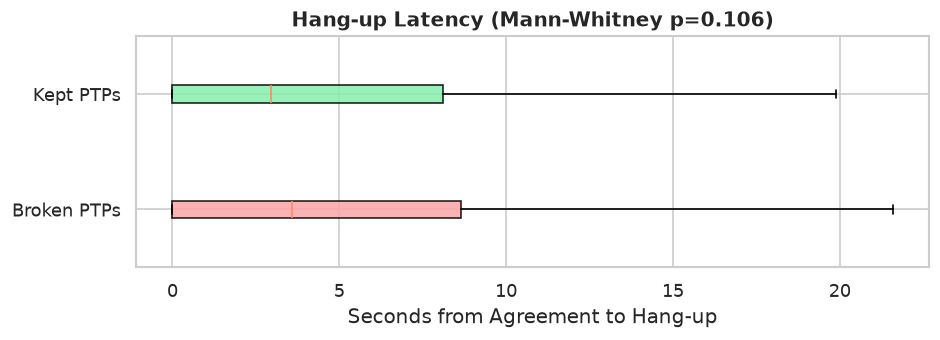

In [322]:
b_s = master_df[(master_df["is_kept"] == 0) & master_df["seconds_to_hangup"].notna()]["seconds_to_hangup"]
k_s = master_df[(master_df["is_kept"] == 1) & master_df["seconds_to_hangup"].notna()]["seconds_to_hangup"]

if len(b_s) > 0 and len(k_s) > 0:
    u_stat, p_mw = mannwhitneyu(b_s, k_s, alternative="two-sided")
    print(f"Kept PTP Median:   {k_s.median():.1f}s (IQR: {k_s.quantile(0.25):.1f}s – {k_s.quantile(0.75):.1f}s)")
    print(f"Broken PTP Median: {b_s.median():.1f}s (IQR: {b_s.quantile(0.25):.1f}s – {b_s.quantile(0.75):.1f}s)")
    print(f"Mann-Whitney U: {u_stat:,.0f}, p = {p_mw:.4f}")

    plt.figure(figsize=(8, 3))
    bp = plt.boxplot([b_s, k_s], vert=False, patch_artist=True, showfliers=False,
                     tick_labels=["Broken PTPs", "Kept PTPs"])
    for patch, color in zip(bp["boxes"], ["#FCA5A5", "#86EFAC"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)
    plt.title(f"Hang-up Latency (Mann-Whitney p={p_mw:.3f})", fontweight="bold")
    plt.xlabel("Seconds from Agreement to Hang-up")
    plt.tight_layout()
    plt.show()

## 5. Financial History & Capacity to Pay
### 5.1 Historical Keep Rate & Repeat Promisers
Past behavior is often the strongest predictor of future actions. We incorporate the borrower's historical record, explicitly calculating their past PTP keep rate and flagging chronic "repeat promisers" who frequently default.

In [323]:
# Historical keep rate
master_df["prev_ptp_count"] = pd.to_numeric(master_df["prev_ptp_count"], errors="coerce").fillna(0)
master_df["prev_ptp_broken"] = pd.to_numeric(master_df["prev_ptp_broken"], errors="coerce").fillna(0)

master_df["historical_keep_rate"] = np.where(
    master_df["prev_ptp_count"] > 0,
    (master_df["prev_ptp_count"] - master_df["prev_ptp_broken"]) / master_df["prev_ptp_count"],
    0.0,
)


### Plot Historical Keep Rate Distribution
We plot a histogram specifically for accounts that have established a meaningful history (≥ 2 past PTPs) to visualize the empirical distribution of reliability.

Accounts with >= 2 past PTPs in train: 1088


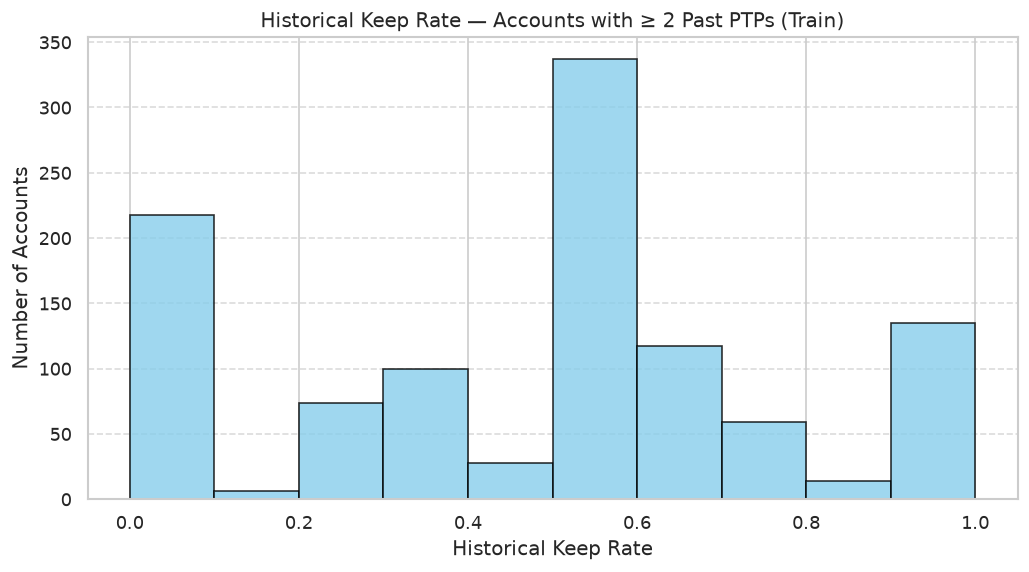

In [324]:
# Histogram for accounts with >= 2 PTPs (train only)
train_df = master_df[master_df["split"] == "train"].copy()
accounts_min_2 = train_df[train_df["prev_ptp_count"] >= 2]
print(f"Accounts with >= 2 past PTPs in train: {len(accounts_min_2)}")

plt.figure(figsize=(10, 5))
plt.hist(accounts_min_2["historical_keep_rate"], bins=10, edgecolor="black", color="skyblue", alpha=0.8)
plt.title("Historical Keep Rate — Accounts with ≥ 2 Past PTPs (Train)")
plt.xlabel("Historical Keep Rate")
plt.ylabel("Number of Accounts")
plt.grid(axis="y", ls="--", alpha=0.7)
plt.show()


### Determine High-Confidence Threshold
We filter for accounts explicitly labeled as "repeat_promiser" by high-confidence annotators to ground our heuristic threshold definition in human-validated truth.

In [325]:
# Repeat promiser threshold from high-confidence labels
rep_promisers = train_df[
    (train_df["annotated_type"] == "repeat_promiser") & (train_df["annotator_confidence"] == "high")
]
if not rep_promisers.empty:
    rep_hk = np.where(
        rep_promisers["prev_ptp_count"] > 0,
        (rep_promisers["prev_ptp_count"] - rep_promisers["prev_ptp_broken"]) / rep_promisers["prev_ptp_count"],
        0.0,
    )
    print(f"Rock-Solid Threshold (high-conf repeat promisers): median keep rate = {np.median(rep_hk):.2f}")


Rock-Solid Threshold (high-conf repeat promisers): median keep rate = 0.00


### Confidence Segment Breakdown
We analyze how the repeat promiser threshold varies across different annotator confidence segments.

In [326]:
# Confidence breakdown
rep_all = train_df[train_df["annotated_type"] == "repeat_promiser"]
if not rep_all.empty:
    rep_all = rep_all.copy()
    rep_all["hist_kr"] = np.where(
        rep_all["prev_ptp_count"] > 0,
        (rep_all["prev_ptp_count"] - rep_all["prev_ptp_broken"]) / rep_all["prev_ptp_count"], 0.0)
    print("\nMedian Keep Rate by Annotator Confidence (repeat_promiser):")
    print(rep_all.groupby("annotator_confidence")["hist_kr"].median())



Median Keep Rate by Annotator Confidence (repeat_promiser):
annotator_confidence
high      0.000000
low       0.666667
medium    0.000000
Name: hist_kr, dtype: float64


### Flagging High-Risk Repeat Promisers
We define a chronic offender class (High-Risk Repeat Promisers) who have multiple past promises but a 0% historical keep rate, cross-tabulating against ground truth.

In [327]:
# Flag
master_df["is_high_risk_repeat_promiser"] = (
    (master_df["prev_ptp_count"] >= 2) & (master_df["historical_keep_rate"] == 0.0)
).astype(int)
print(f"\nFlagged {master_df['is_high_risk_repeat_promiser'].sum()} high-risk repeat promisers.")

# Cross-tab with annotated_type
print("\nCross-tab with Ground Truth:")
display(pd.crosstab(master_df["annotated_type"], master_df["is_high_risk_repeat_promiser"], margins=True))



Flagged 297 high-risk repeat promisers.

Cross-tab with Ground Truth:


is_high_risk_repeat_promiser,0,1,All
annotated_type,,,
agent_recorded_or_pushed,12,1,13
escape,35,0,35
genuine_feasible,53,1,54
genuine_infeasible,46,5,51
repeat_promiser,25,4,29
third_party,16,2,18
All,187,13,200


### 5.2 Salary Proximity Score (Cash-Flow Hypothesis)
Borrowers have higher liquidity immediately following their salary credit dates. We compute a `salary_proximity_score` that mathematically decays the probability of keeping a promise the further the promised date is from the borrower's typical payday.

In [328]:
master_df["typical_salary_day"] = pd.to_numeric(master_df["salary_credit_day"], errors="coerce")
master_df["promised_day"] = master_df["promised_date"].dt.day

def calc_dist(sal, prom):
    if pd.isna(sal) or pd.isna(prom):
        return np.nan
    diff = abs(sal - prom)
    return min(diff, 30 - diff)


### Apply Salary Proximity Transformation
We apply the decay function across the entire dataset to compute the final proximity score feature.

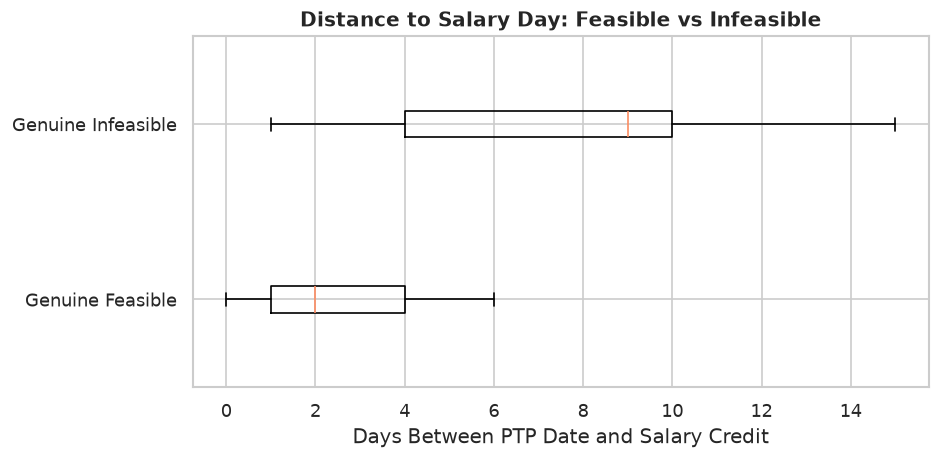

Salary proximity score computed. Non-null: 1162


In [329]:
master_df["salary_proximity_score"] = master_df.apply(
    lambda r: calc_dist(r["typical_salary_day"], r["promised_day"]), axis=1
)

mask_f = master_df["annotated_type"] == "genuine_feasible"
mask_i = master_df["annotated_type"] == "genuine_infeasible"
if mask_f.any() and mask_i.any():
    plt.figure(figsize=(8, 4))
    plt.boxplot(
        [master_df[mask_f]["salary_proximity_score"].dropna(),
         master_df[mask_i]["salary_proximity_score"].dropna()],
        vert=False, tick_labels=["Genuine Feasible", "Genuine Infeasible"],
    )
    plt.title("Distance to Salary Day: Feasible vs Infeasible", fontweight="bold")
    plt.xlabel("Days Between PTP Date and Salary Credit")
    plt.tight_layout()
    plt.show()

print(f"Salary proximity score computed. Non-null: {master_df['salary_proximity_score'].notna().sum()}")


### 6.3 Composite Hardship Index
Borrowers often cite specific hardship reasons (e.g., medical, job loss) for non-payment. We construct a composite index weighting these explicit hardship indicators to proxy the borrower's overall capacity to pay.

In [330]:
def assign_hardship(reason):
    if pd.isna(reason):
        return 0
    r = str(reason).lower()
    if any(k in r for k in ["insufficient", "funds", "balance", "debit"]):
        return 2
    elif any(k in r for k in ["technical", "network", "system"]):
        return 0
    return 1

if "last_bounce_reason" in master_df.columns:
    master_df["hardship_score"] = master_df["last_bounce_reason"].apply(assign_hardship)
else:
    master_df["hardship_score"] = 0

dpd_col = "dpd_start" if "dpd_start" in master_df.columns else "dpd"
if dpd_col in master_df.columns:
    master_df["dpd_days"] = pd.to_numeric(master_df[dpd_col], errors="coerce").fillna(0)
    master_df["composite_hardship_index"] = master_df["hardship_score"] * np.log1p(
        master_df["dpd_days"].clip(lower=0)
    )
    print("Mean Composite Hardship Index by Ground Truth:")
    print(master_df.groupby("annotated_type")["composite_hardship_index"].mean().round(2))



Mean Composite Hardship Index by Ground Truth:
annotated_type
agent_recorded_or_pushed    6.21
escape                      5.63
genuine_feasible            5.74
genuine_infeasible          5.43
repeat_promiser             6.10
third_party                 4.63
Name: composite_hardship_index, dtype: float64


## 6. Post-Call Engagement Tracking
### 6.1 The 24-Hour Digital Window
Intent can often be tracked digitally post-conversation. We isolate user actions (app logins, payment link clicks) that occur within a strict 24-hour window following the PTP capture.

In [331]:
events = post_call_raw.merge(master_df[["ptp_id", "captured_ts"]], on="ptp_id", how="inner")
events["hours_after"] = (events["event_ts"] - events["captured_ts"]).dt.total_seconds() / 3600
events_24h = events[(events["hours_after"] >= 0) & (events["hours_after"] <= 24)].copy()

print(f"Total post-call events: {len(events)}")
print(f"Events within 24 hours: {len(events_24h)}")
print(f"PTPs with at least one 24h event: {events_24h['ptp_id'].nunique()}")

# Event type distribution
print("\nEvent Type Distribution (24h):")
print(events_24h["event_type"].value_counts())

Total post-call events: 8466
Events within 24 hours: 5541
PTPs with at least one 24h event: 2944

Event Type Distribution (24h):
event_type
payment_link_sent             2393
whatsapp_confirmation_sent    1822
payment_link_opened            900
confirmation_reply_yes         289
inbound_call_from_customer      79
confirmation_reply_no           58
Name: count, dtype: int64


### 6.2 Event Count Pivoting & Digital Intent Index
We pivot the raw time-series event data to count specific actions per borrower. We then aggregate these counts into a `digital_intent_index`, quantifying the borrower's post-call behavioral momentum toward fulfillment.

In [332]:
ev_counts = events_24h.groupby(["ptp_id", "event_type"]).size().unstack(fill_value=0).reset_index()
ev_counts.columns = ["ptp_id"] + [f"event24h_{c}" for c in ev_counts.columns[1:]]

# Merge ONLY event columns (avoid fillna on everything)
master_df = master_df.merge(ev_counts, on="ptp_id", how="left")
event_cols = [c for c in ev_counts.columns if c.startswith("event24h_")]
master_df[event_cols] = master_df[event_cols].fillna(0)

# Ensure expected event columns exist
expected_events = ["payment_link_opened", "confirmation_reply_yes", "confirmation_reply_no",
                   "inbound_call_from_customer"]
for event in expected_events:
    col = "event24h_" + event
    if col not in master_df.columns:
        master_df[col] = 0


### Compute Digital Touchpoints & Intent Index
We synthesize the raw event counts into a discrete `digital_touchpoints` sum and a weighted `digital_intent_index` to quantify post-call momentum.

In [333]:
# Digital touchpoints & intent index
master_df["digital_touchpoints_24h"] = (
    (master_df["event24h_payment_link_opened"] > 0).astype(int)
    + (master_df["event24h_confirmation_reply_yes"] > 0).astype(int)
    + (master_df["event24h_confirmation_reply_no"] > 0).astype(int)
    + (master_df["event24h_inbound_call_from_customer"] > 0).astype(int)
)

master_df["digital_intent_index_24h"] = (
    (master_df["event24h_payment_link_opened"] > 0).astype(int)
    + (master_df["event24h_confirmation_reply_yes"] > 0).astype(int)
    + (master_df["event24h_inbound_call_from_customer"] > 0).astype(int)
    - (master_df["event24h_confirmation_reply_no"] > 0).astype(int)
)


### Engineering Event Timing Signatures
Beyond count aggregates, the span and recency of digital events (e.g., first event timestamp, last event timestamp) provide subtle signals of borrower urgency.

In [334]:
# Event timing features
event_timing = events_24h.groupby("ptp_id").agg(
    first_event24h_ts=("event_ts", "min"),
    last_event24h_ts=("event_ts", "max"),
    unique_event_types24h=("event_type", "nunique"),
    total_event_count24h=("event_type", "size"),
).reset_index()
master_df = master_df.merge(event_timing, on="ptp_id", how="left")

print("Digital Intent Index Profile:")
print(master_df["digital_intent_index_24h"].value_counts().sort_index())


Digital Intent Index Profile:
digital_intent_index_24h
-1      41
 0    2549
 1    1003
 2     102
 3       1
Name: count, dtype: int64


### 6.3 Post-Call Engagement Validation
We validate the `digital_intent_index` by observing the actual fulfillment rates across different index tiers, confirming that higher digital engagement strongly correlates with genuine intent to pay.

In [335]:
# Fulfillment rate by intent index
intent_fulfilment = master_df.groupby("digital_intent_index_24h").agg(
    PTPs=("ptp_id", "count"), fulfilled=("is_kept", "sum")
).reset_index()
intent_fulfilment["fulfilment_rate"] = intent_fulfilment["fulfilled"] / intent_fulfilment["PTPs"] * 100

print("Fulfillment by Digital Intent Index:")
display(intent_fulfilment)

# Chi-square test
contingency = pd.crosstab(master_df["digital_intent_index_24h"], master_df["is_kept"])
if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
    chi2_di, p_di, _, _ = chi2_contingency(contingency)
    print(f"\nChi-square: {chi2_di:.2f}, p-value: {p_di:.4e}")


Fulfillment by Digital Intent Index:


,digital_intent_index_24h,PTPs,fulfilled,fulfilment_rate
0,-1,41,6,14.634146
1,0,2549,574,22.518635
2,1,1003,396,39.481555
3,2,102,55,53.921569
4,3,1,0,0.000000



Chi-square: 141.90, p-value: 1.1067e-29


### Specific Touchpoint Drill-Down Analysis
Beyond the composite index, we perform isolated analyses on specific high-signal events (like opening the payment link or replying 'YES' to the SMS) to confirm their individual predictive power.

In [336]:
# Payment link opened analysis
master_df["link_opened"] = (master_df["event24h_payment_link_opened"] > 0).astype(int)
link_analysis = master_df.groupby("link_opened").agg(
    PTPs=("ptp_id", "count"), fulfilled=("is_kept", "sum")
).reset_index()
link_analysis["fulfilment_rate"] = link_analysis["fulfilled"] / link_analysis["PTPs"] * 100
print("\nPayment Link Opened Analysis:")
display(link_analysis)



Payment Link Opened Analysis:


,link_opened,PTPs,fulfilled,fulfilment_rate
0,0,2837,664,23.405005
1,1,859,367,42.724098


### Post-Call Validation: SMS Confirmation
Similarly, we isolate users who explicitly replied 'YES' to a confirmation SMS to validate its predictive strength.

In [337]:
# YES/NO confirmation analysis
master_df["yes_confirmation"] = (master_df["event24h_confirmation_reply_yes"] > 0).astype(int)
yes_analysis = master_df.groupby("yes_confirmation").agg(
    PTPs=("ptp_id", "count"), fulfilled=("is_kept", "sum")
).reset_index()
yes_analysis["fulfilment_rate"] = yes_analysis["fulfilled"] / yes_analysis["PTPs"] * 100
print("\nYES Confirmation Analysis:")
display(yes_analysis)



YES Confirmation Analysis:


,yes_confirmation,PTPs,fulfilled,fulfilment_rate
0,0,3407,902,26.474905
1,1,289,129,44.636678


### Post-Call Validation: Total Touchpoints
Finally, we evaluate if sheer volume of digital interaction (total touchpoint count) holds independent predictive power.

In [338]:
# Touchpoint count analysis
touchpoint_analysis = master_df.groupby("digital_touchpoints_24h").agg(
    PTPs=("ptp_id", "count"), fulfilled=("is_kept", "sum")
).reset_index()
touchpoint_analysis["fulfilment_rate"] = touchpoint_analysis["fulfilled"] / touchpoint_analysis["PTPs"] * 100
print("\nDigital Touchpoint Count Analysis:")
display(touchpoint_analysis)



Digital Touchpoint Count Analysis:


,digital_touchpoints_24h,PTPs,fulfilled,fulfilment_rate
0,0,2532,571,22.551343
1,1,1044,402,38.505747
2,2,119,58,48.739496
3,3,1,0,0.000000


### Digital Intent Visual Confirmation
We present bar charts contrasting intent fulfillment tiers, definitively proving that higher post-call digital engagement directly correlates with kept promises.

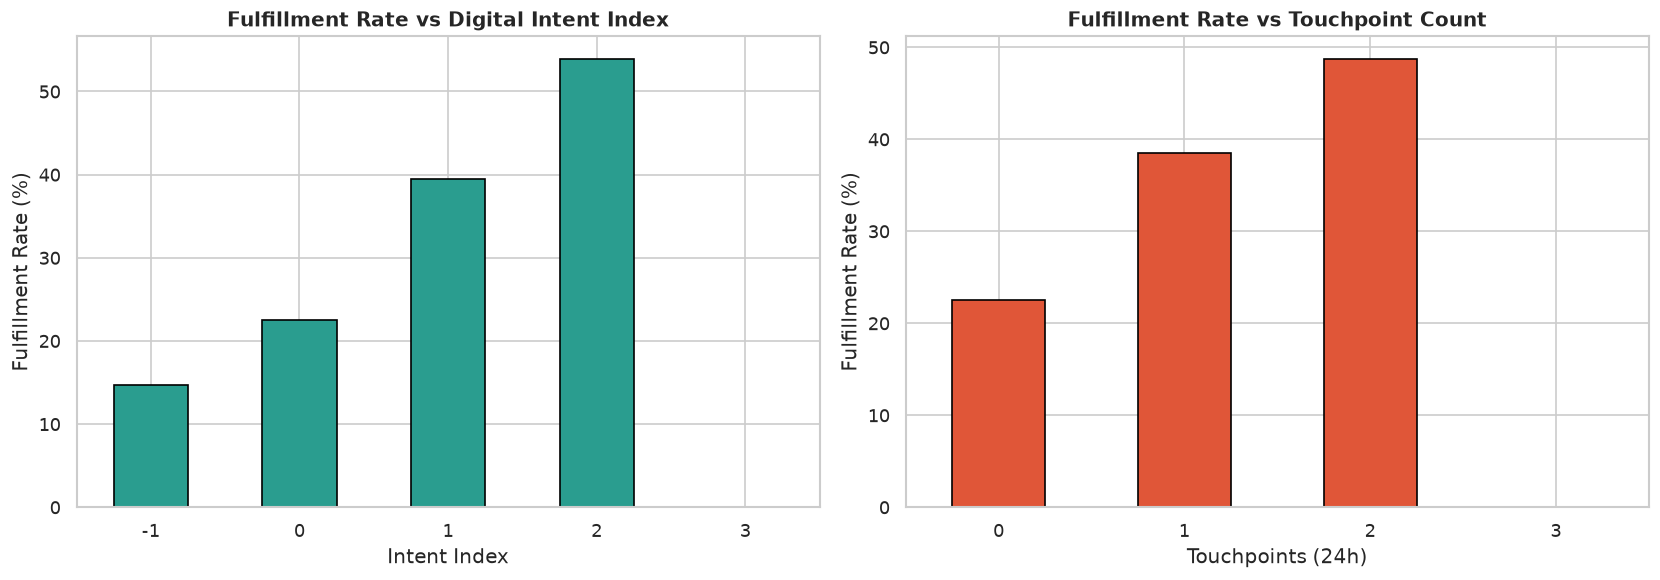

In [339]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
intent_fulfilment.plot(x="digital_intent_index_24h", y="fulfilment_rate", kind="bar",
                       ax=axes[0], color=ACCENT_GREEN, edgecolor="black", legend=False)
axes[0].set_title("Fulfillment Rate vs Digital Intent Index", fontweight="bold")
axes[0].set_ylabel("Fulfillment Rate (%)")
axes[0].set_xlabel("Intent Index")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

touchpoint_analysis.plot(x="digital_touchpoints_24h", y="fulfilment_rate", kind="bar",
                         ax=axes[1], color=ACCENT_CORAL, edgecolor="black", legend=False)
axes[1].set_title("Fulfillment Rate vs Touchpoint Count", fontweight="bold")
axes[1].set_ylabel("Fulfillment Rate (%)")
axes[1].set_xlabel("Touchpoints (24h)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()


## 7. Final Feature Matrix Export
We have systematically constructed a feature space encompassing agent dynamics, NLP linguistics, financial history, and digital tracking. We finalize our analytical dataset by selecting the engineered columns and persisting the matrix to disk for the Machine Learning pipeline.

In [340]:
export_cols = [
    "ptp_id", "account_id", "split", "is_kept", "annotated_type",
    "confidence_weight", "is_unreliable_label",
    "language_team_encoded", "shift_bunching_flag",
    "has_hedge", "has_condition", "has_vague", "has_firm",
    "category_A_uncertainty", "category_B_conditional",
    "borrower_proposed_date", "agent_proposed_date", "seconds_to_hangup",
    "historical_keep_rate", "is_high_risk_repeat_promiser",
    "salary_proximity_score", "hardship_score", "composite_hardship_index",
    "digital_touchpoints_24h", "digital_intent_index_24h",
]

final_cols = [c for c in export_cols if c in master_df.columns]
lender_cols = [c for c in master_df.columns if c.startswith("lender_")
               and c not in ("lender_id", "lender_type", "lender_name")]
final_features_df = master_df[final_cols + lender_cols]


print(f"Pipeline Execution Complete.")
print(f"\nFeature columns: {list(final_features_df.columns)}")

Pipeline Execution Complete.

Feature columns: ['ptp_id', 'account_id', 'split', 'is_kept', 'annotated_type', 'confidence_weight', 'is_unreliable_label', 'language_team_encoded', 'shift_bunching_flag', 'has_hedge', 'has_condition', 'has_vague', 'has_firm', 'category_A_uncertainty', 'category_B_conditional', 'borrower_proposed_date', 'agent_proposed_date', 'seconds_to_hangup', 'historical_keep_rate', 'is_high_risk_repeat_promiser', 'salary_proximity_score', 'hardship_score', 'composite_hardship_index', 'digital_touchpoints_24h', 'digital_intent_index_24h', 'lender_Fintech NBFC', 'lender_NBFC', 'lender_NBFC (MSME)', 'lender_NBFC-MFI', 'lender_Private bank', 'lender_Small finance bank']


## 8. End-to-End Machine Learning Pipeline
### 8.1 Imports for Machine Learning
Import scikit-learn and xgboost modules required for preprocessing, model building, hyperparameter tuning, and evaluation.

In [341]:
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, accuracy_score, precision_recall_curve, classification_report, PrecisionRecallDisplay
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
import joblib
import matplotlib.pyplot as plt


### 8.2 Prepare Text Features (TF-IDF)
For the raw transcript text, we will utilize Term Frequency-Inverse Document Frequency (TF-IDF) vectorization. This captures the broader lexical context of the conversations beyond our manually engineered linguistic hedge features.

In [342]:
# Use transcripts_raw and dial_raw already in memory from EDA
trans = transcripts_raw.copy()
dial = dial_raw.copy()

trans['speaker_text'] = trans['speaker'] + ': ' + trans['text'].astype(str)
full_text = trans.groupby('call_id')['speaker_text'].apply(lambda x: ' '.join(x)).reset_index()
full_text.rename(columns={'call_id': 'attempt_id', 'speaker_text': 'full_text'}, inplace=True)

dial_map = dial[['attempt_id', 'ptp_id']].dropna().drop_duplicates()
full_text = full_text.merge(dial_map, on='attempt_id', how='inner')
full_text = full_text[['ptp_id', 'full_text']].groupby('ptp_id')['full_text'].first().reset_index()

final_features_df = final_features_df.merge(full_text, on='ptp_id', how='left')
final_features_df['full_text'] = final_features_df['full_text'].fillna('')


### 8.3 Define Feature Groups and Formulate the Target
**Crucial Business Logic:** The core business objective is to intercept and prevent *Fake* promises. Therefore, we explicitly define our supervised learning target as `is_fake = 1 - is_kept`. This focuses the models on predicting the minority class of interest.

In [343]:
numerical_features = [
    'seconds_to_hangup', 'salary_proximity_score', 'historical_keep_rate',
    'hardship_score', 'composite_hardship_index'
]
categorical_features = [
    'language_team_encoded', 'shift_bunching_flag', 'has_hedge', 'has_condition', 
    'has_vague', 'has_firm', 'category_A_uncertainty', 'category_B_conditional', 
    'borrower_proposed_date', 'agent_proposed_date', 'is_high_risk_repeat_promiser'
] + [c for c in final_features_df.columns if c.startswith('lender_')]

text_feature = 'full_text'
features = numerical_features + categorical_features + [text_feature]

# CRITICAL FIX: Fake PTPs are the target of interest
final_features_df['is_fake'] = 1 - final_features_df['is_kept']
target = 'is_fake'


### 8.4 Train, Validation, and Test Splits
We partition the data using our pre-defined, time-aware splits. We ensure our validation set is used for hyperparameter and threshold tuning, strictly reserving the test set for an unbiased final evaluation.

In [344]:
train_mask = final_features_df['split'] == 'train'
val_mask = final_features_df['split'] == 'validation'
test_mask = final_features_df['split'] == 'test'

X_train, y_train = final_features_df.loc[train_mask, features], final_features_df.loc[train_mask, target]
X_val, y_val = final_features_df.loc[val_mask, features], final_features_df.loc[val_mask, target]
X_test, y_test = final_features_df.loc[test_mask, features], final_features_df.loc[test_mask, target]


### 8.5 Build Heterogeneous Data Preprocessor
Our feature space contains numerical vectors, categorical classes, and raw text. We construct a unified `scikit-learn` ColumnTransformer pipeline to handle imputation, standard scaling, one-hot encoding, and TF-IDF vectorization simultaneously.

In [345]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numerical_features),
        ('cat', SimpleImputer(strategy='most_frequent'), categorical_features),
        ('tfidf', TfidfVectorizer(max_features=1000, ngram_range=(1, 2)), text_feature)
    ],
    remainder='drop'
)


### 8.6 Hyperparameter Optimization & Threshold Tuning Strategy
In highly imbalanced datasets, standard accuracy is misleading, and the default 0.5 decision boundary is often suboptimal. 
We define a comprehensive training function that:
1. Optimizes hyperparameters via Stratified Cross-Validation using `GridSearchCV`.
2. Selects the best estimator and dynamically tunes the probability decision threshold on the Validation set to maximize the F1-Score.
3. Evaluates the tuned model on the untouched Test set.

In [346]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def grid_search_and_evaluate(clf, param_grid, name, to_dense=False):
    print(f'--- Grid Search for {name} ---')
    
    if to_dense:
        pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('to_dense', FunctionTransformer(lambda x: x.toarray(), accept_sparse=True)),
            ('clf', clf)
        ])
    else:
        pipe = Pipeline([('preprocessor', preprocessor), ('clf', clf)])
    
    grid = GridSearchCV(
        pipe, 
        param_grid=param_grid, 
        cv=cv_strategy, 
        scoring='average_precision', 
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    best_pipe = grid.best_estimator_
    print(f'Best Params: {grid.best_params_}')
    
    # Tune Threshold on Validation Set
    y_val_prob = best_pipe.predict_proba(X_val)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]
    
    # Evaluate on Test Set
    y_test_prob = best_pipe.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_prob >= best_threshold).astype(int)
    
    print(f'\n{name} (Test Set Performance):')
    print(f'PR-AUC: {average_precision_score(y_test, y_test_prob):.4f}')
    print(f'F1-Score: {f1_score(y_test, y_test_pred):.4f}')
    print(f'Precision: {precision_score(y_test, y_test_pred):.4f}')
    print(f'Recall: {recall_score(y_test, y_test_pred):.4f}\n')
    return best_pipe


### 8.7 Baseline 1: Logistic Regression
We establish our first baseline using a linear model. Logistic regression provides high interpretability and serves as a sanity check against more complex, non-linear algorithms.

In [347]:
lr_clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_params = {
    'clf__C': [0.1, 1.0, 10.0]
}
lr_best_pipe = grid_search_and_evaluate(lr_clf, lr_params, 'Logistic Regression')


--- Grid Search for Logistic Regression ---
Best Params: {'clf__C': 1.0}

Logistic Regression (Test Set Performance):
PR-AUC: 0.8262
F1-Score: 0.8421
Precision: 0.7299
Recall: 0.9950



### 8.8 Baseline 2: Decision Tree
We test a single Decision Tree to establish a non-linear benchmark. While prone to overfitting, it provides excellent interpretability regarding feature splitting thresholds.

In [348]:
dt_clf = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt_params = {
    'clf__max_depth': [3, 5, None],
    'clf__min_samples_split': [2, 10]
}
dt_best_pipe = grid_search_and_evaluate(dt_clf, dt_params, 'Decision Tree')


--- Grid Search for Decision Tree ---
Best Params: {'clf__max_depth': 3, 'clf__min_samples_split': 2}

Decision Tree (Test Set Performance):
PR-AUC: 0.7685
F1-Score: 0.8332
Precision: 0.7140
Recall: 1.0000



### 8.9 Baseline 3: Random Forest
We extend the tree-based approach using Random Forest, an ensemble bagging technique that reduces the variance of individual decision trees and provides robust out-of-the-box performance.

In [349]:
rf_clf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf_params = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [5, 10, None]
}
rf_best_pipe = grid_search_and_evaluate(rf_clf, rf_params, 'Random Forest')


--- Grid Search for Random Forest ---
Best Params: {'clf__max_depth': 10, 'clf__n_estimators': 200}

Random Forest (Test Set Performance):
PR-AUC: 0.8278
F1-Score: 0.8426
Precision: 0.7361
Recall: 0.9851



### 8.10 Baseline 4: Naive Bayes
We evaluate Gaussian Naive Bayes, a generative model based on probabilistic assumptions. Since GaussianNB requires dense arrays, we integrate a custom transformer to convert sparse TF-IDF matrices on the fly.

In [350]:
gnb_clf = GaussianNB()
gnb_params = {
    'clf__var_smoothing': [1e-9, 1e-8, 1e-7]
}
gnb_best_pipe = grid_search_and_evaluate(gnb_clf, gnb_params, 'Naive Bayes', to_dense=True)


--- Grid Search for Naive Bayes ---


Best Params: {'clf__var_smoothing': 1e-07}

Naive Bayes (Test Set Performance):
PR-AUC: 0.8231
F1-Score: 0.8363
Precision: 0.7199
Recall: 0.9975



### 8.11 Baseline 5: Gradient Boosting Classifier
We evaluate a standard Gradient Boosting model, an ensemble boosting technique that builds sequential trees to correct the residual errors of prior iterations.

In [351]:
gb_clf = GradientBoostingClassifier(random_state=42)
gb_params = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 4]
}
gb_best_pipe = grid_search_and_evaluate(gb_clf, gb_params, 'Gradient Boosting')


--- Grid Search for Gradient Boosting ---
Best Params: {'clf__max_depth': 3, 'clf__n_estimators': 100}

Gradient Boosting (Test Set Performance):
PR-AUC: 0.8336
F1-Score: 0.8447
Precision: 0.7379
Recall: 0.9876



### 8.12 Final Model: Tuned XGBoost (eXtreme Gradient Boosting)
For our premier model, we employ XGBoost. It offers advanced regularization, superior handling of missing values, and natively supports `scale_pos_weight` to aggressively penalize misclassifications of the minority (Fake PTP) class.

In [352]:
neg = len(y_train) - sum(y_train)
pos = sum(y_train)
scale_pos_weight = neg / pos

xgb_clf = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr',
    random_state=42
)

xgb_params = {
    'clf__n_estimators': [200, 400],
    'clf__max_depth': [3, 4, 5],
    'clf__learning_rate': [0.03, 0.05],
    'clf__subsample': [0.8],
    'clf__colsample_bytree': [0.8]
}
xgb_best_pipe = grid_search_and_evaluate(xgb_clf, xgb_params, 'XGBoost')


--- Grid Search for XGBoost ---


Best Params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 0.8}

XGBoost (Test Set Performance):
PR-AUC: 0.8341
F1-Score: 0.8458
Precision: 0.7425
Recall: 0.9826



### 8.13 Model Evaluation: Precision-Recall Curves
Because our classes are imbalanced and we prioritize the detection of Fake PTPs, ROC-AUC is overly optimistic. We evaluate all models using Precision-Recall (PR) Curves and the PR-AUC metric, visually confirming XGBoost's dominance across the threshold spectrum.

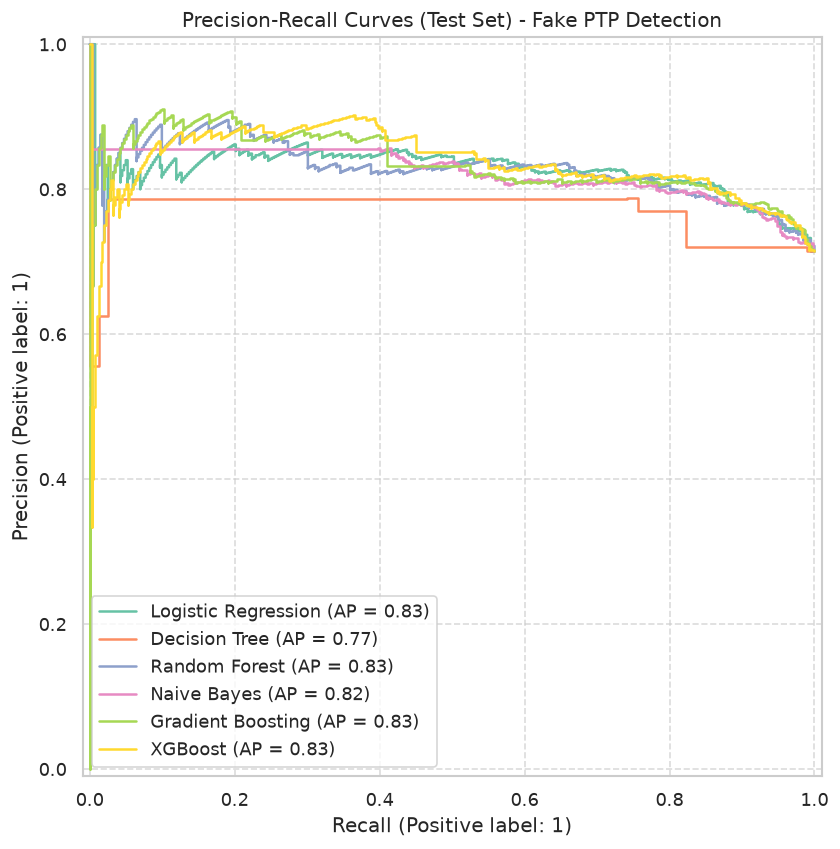

In [353]:
models = {
    'Logistic Regression': lr_best_pipe,
    'Decision Tree': dt_best_pipe,
    'Random Forest': rf_best_pipe,
    'Naive Bayes': gnb_best_pipe,
    'Gradient Boosting': gb_best_pipe,
    'XGBoost': xgb_best_pipe
}

fig, ax = plt.subplots(figsize=(10, 8))

for name, pipe in models.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)

plt.title('Precision-Recall Curves (Test Set) - Fake PTP Detection')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower left')
plt.show()


### 8.14 Final Model Serialization
Having identified XGBoost as the superior model with an optimized decision threshold, we serialize the complete pipeline (including the preprocessor, TF-IDF vectorizer, and tuned estimator) using `joblib` for seamless production deployment.

In [354]:
joblib.dump(xgb_best_pipe, 'outputs/fake_ptp_xgboost_pipeline.pkl')
print('Exported best XGBoost pipeline to outputs/fake_ptp_xgboost_pipeline.pkl')


Exported best XGBoost pipeline to outputs/fake_ptp_xgboost_pipeline.pkl
